# Project DTW: *Guitar Tuner* dan Cek Chord Gitar
Pengembangan dari studi kasus DTW Minggu 11 (pengenalan ucapan angka), Data Mining · ITS.

Proyek ini terdiri dari dua bagian dengan tingkat kesulitan yang naik:

| | **Bagian 1: Tuner (nada tunggal)** | **Bagian 2: Cek chord ** |
|---|---|---|
| Pertanyaan | Senar mana yang dipetik, dan berapa *cent* lagi? | Chord apa yang digenjreng, dan apakah sudah benar? |
| Kelas | 6 senar lepas: E2, A2, D3, G3, B3, E4 | 8 chord dasar: C, D, E, G, A, Am, Em, Dm |
| Fitur utama | **semiton** (perlu membedakan oktaf) | **chroma** (yang menentukan chord adalah nama nada, bukan oktaf) |
| Baseline | YIN: estimasi frekuensi dasar | Template chord biner pada rata-rata chroma |
| Peran DTW | Panjang bunyi berbeda | Urutan senar dan kecepatan genjrengan berbeda |
| Evaluasi | Akurasi, presisi/recall/F1, CI 95%, uji McNemar, ketepatan *cent* | Sama, ditambah **verifikasi benar/salah** (ROC-AUC, sensitivitas, spesifisitas) |

Di kedua bagian, metode intinya sama dengan notebook kelas: **fitur → jarak (Euclid vs DTW) → 1-NN ke template**.

**Data.** [NSynth](https://magenta.tensorflow.org/datasets/nsynth) (Google Magenta, CC BY 4.0), versi **JSON/WAV**:
- `nsynth-valid.jsonwav.tar.gz` → sumber **template** (satu gitar);
- `nsynth-test.jsonwav.tar.gz` → **data uji** (gitar lain; instrumen di valid dan test tidak tumpang tindih).

Letakkan kedua file `.tar.gz` di folder yang sama dengan notebook. **Bagian 0** akan mengekstrak hanya yang dibutuhkan: `examples.json` dan nada gitar MIDI 40–68 (E2 sampai G#4). Nada-nada ini cukup untuk 6 senar lepas, untuk merakit 8 chord, dan untuk membuat chord yang sengaja salah.

NSynth hanya berisi nada tunggal, jadi **genjrengan chord dirakit** dari nada-nada gitar NSynth dengan instrumen yang sama, diberi jeda beberapa milidetik antarsenar seperti genjrengan sungguhan.

> **Belum ada NSynth?** Notebook tetap jalan dengan **bunyi gitar sintetis** (Karplus–Strong) berformat sama. Hasil pada data sintetis hanya untuk mencoba alur, bukan untuk dilaporkan.

Library: `numpy`, `scipy`, `pandas`, `matplotlib`, `jinja2` (pewarnaan tabel). `librosa` opsional (Lampiran G).

## 0. Persiapan

In [2]:
import os, json, time, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import resample, resample_poly, lfilter, fftconvolve
from scipy.fft import rfft, rfftfreq, dct
from scipy.stats import binomtest, norm
from math import gcd
try:
    from IPython.display import display, Audio
except ImportError:                     # bila dijalankan sebagai skrip biasa
    display, Audio = print, None

SR = 16000                              # NSynth: mono 16 kHz
SENAR = {40: "E2", 45: "A2", 50: "D3", 55: "G3", 59: "B3", 64: "E4"}
PITCH = list(SENAR)                     # urutan kelas
LABEL = [SENAR[p] for p in PITCH]
NAMA_NADA = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]

# Bagian 2: chord terbuka (open chord) gitar, nada MIDI dari senar 6 (bawah) ke senar 1 (atas)
CHORD = {
    "C":  [48, 52, 55, 60, 64],        # x 3 2 0 1 0
    "D":  [50, 57, 62, 66],            # x x 0 2 3 2
    "E":  [40, 47, 52, 56, 59, 64],    # 0 2 2 1 0 0
    "G":  [43, 47, 50, 55, 59, 67],    # 3 2 0 0 0 3
    "A":  [45, 52, 57, 61, 64],        # x 0 2 2 2 0
    "Am": [45, 52, 57, 60, 64],        # x 0 2 2 1 0
    "Em": [40, 47, 52, 55, 59, 64],    # 0 2 2 0 0 0
    "Dm": [50, 57, 62, 65],            # x x 0 2 3 1
}
NAMA_CHORD = list(CHORD)
NADA_DIBUTUHKAN = list(range(40, 69))  # E2..G#4: senar lepas, semua nada chord, dan nada tetangganya

def midi_ke_hz(m): return 440.0 * 2 ** ((m - 69) / 12)
def hz_ke_midi(f): return 69 + 12 * np.log2(f / 440.0)
def nama_nada(m):  m = int(round(m)); return f"{NAMA_NADA[m % 12]}{m // 12 - 1}"

WARNA = ["#004998", "#F5AA2D", "#1E8E3E", "#C62828", "#6B7280", "#7B1FA2"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.5 | pandas 3.1.1


### 0.1 Ekstraksi data NSynth (cukup sekali)
Sel ini membaca kedua arsip `.tar.gz` dan hanya mengekstrak `examples.json` serta nada gitar MIDI 40–68. Arsip dibaca berurutan satu kali jalan, jadi prosesnya bisa beberapa menit. Setelah selesai, sel ini membuat file penanda sehingga tidak diulang saat notebook dijalankan lagi.

In [3]:
import tarfile, re
pola_nada = "|".join(f"{p:03d}" for p in NADA_DIBUTUHKAN)
pola = re.compile(rf"audio/guitar_.*-({pola_nada})-\d{{3}}\.wav$")

for split in ["nsynth-valid", "nsynth-test"]:
    arsip, penanda = f"{split}.jsonwav.tar.gz", os.path.join(split, ".ekstrak_v2_selesai")
    if os.path.exists(penanda):
        print(f"{split}: sudah diekstrak sebelumnya"); continue
    if not os.path.exists(arsip):
        print(f"{split}: arsip {arsip} tidak ditemukan (dilewati)"); continue
    n, t0 = 0, time.time()
    with tarfile.open(arsip, "r|gz") as tar:            # dibaca berurutan, sekali jalan
        for m in tar:
            if m.name.endswith("examples.json") or pola.search(m.name):
                if not os.path.exists(m.name):
                    tar.extract(m, ".")
                n += 1
    open(penanda, "w").write("ok")
    print(f"{split}: {n} file siap ({time.time() - t0:.0f} detik)")

nsynth-valid: 719 file siap (7 detik)
nsynth-test: 226 file siap (2 detik)


## Bagian A. DTW dari nol (dipakai di kedua bagian)

Fungsi yang sama dengan notebook kelas, dengan satu penyesuaian kecil: batas jendela Sakoe–Chiba dihitung dari diagonal yang diregangkan sehingga jendela tetap tersambung walaupun panjang template dan uji berbeda jauh (misalnya 4 detik vs 0,8 detik).

$$D(i,j)=c(i,j)+\min\{D(i-1,j-1),\ D(i-1,j),\ D(i,j-1)\},\qquad D(0,0)=0,$$

dengan $c(i,j)$ = jarak Euclid antarvektor fitur (DTW multivariat). Parameter `band` mengaktifkan jendela Sakoe–Chiba.

In [4]:
def dtw(x, y, band=None, metric="abs"):
    # Kembalikan (jarak DTW, matriks akumulasi D, jalur warping 0-based)
    x, y = np.asarray(x, float), np.asarray(y, float)
    if x.ndim == 1:
        C = np.abs(x[:, None] - y[None, :]) if metric == "abs" else (x[:, None] - y[None, :]) ** 2
    else:                                   # multivariat: jarak Euclid antarvektor (baris = waktu)
        C = np.sqrt(((x[:, None, :] - y[None, :, :]) ** 2).sum(-1))
    n, m = C.shape
    D = np.full((n + 1, m + 1), np.inf); D[0, 0] = 0.0
    for i in range(1, n + 1):
        lo, hi = 1, m
        if band is not None:                # jendela Sakoe-Chiba di sekitar diagonal yang diregangkan
            lo = max(1, int(np.floor((i - 1) * m / n)) + 1 - band)
            hi = min(m, int(np.ceil(i * m / n)) + band)
        for j in range(lo, hi + 1):
            D[i, j] = C[i-1, j-1] + min(D[i-1, j-1], D[i-1, j], D[i, j-1])
    if not np.isfinite(D[n, m]):            # jendela terlalu sempit: tidak ada jalur
        return np.inf, D[1:, 1:], np.empty((0, 2), int)
    # backtracking dari (n, m) ke (1, 1); urutan pemeriksaan: diagonal, atas, kiri
    i, j, path = n, m, [(n - 1, m - 1)]
    while (i, j) != (1, 1):
        langkah = [(i-1, j-1), (i-1, j), (i, j-1)]
        i, j = langkah[int(np.argmin([D[a, b] for a, b in langkah]))]
        path.append((i - 1, j - 1))
    return D[n, m], D[1:, 1:], np.array(path[::-1])

# cek dengan contoh hitung di slide: hasilnya harus 2
print("DTW contoh slide =", dtw([0, 5, 6, 5, 1], [0, 0, 6, 4, 1, 1])[0])

DTW contoh slide = 2.0


## Bagian B. Data

### B.1 Memuat metadata NSynth (atau membuat data sintetis)
Kita ambil hanya keluarga **guitar** dengan nada MIDI 40–68. Bagian 1 memakai 6 nada senar lepas (40, 45, 50, 55, 59, 64), sedangkan Bagian 2 memakai semua nada itu untuk merakit chord. Nama file NSynth berformat `<instrumen>-<pitch>-<velocity>.wav`, misalnya `guitar_acoustic_010-045-075.wav` = gitar akustik, A2, velocity 75.

In [5]:
def baca_meta(folder):
    p = os.path.join(folder, "examples.json")
    if not os.path.exists(p):
        return None
    m = pd.DataFrame(json.load(open(p))).T
    m["pitch"], m["velocity"] = m.pitch.astype(int), m.velocity.astype(int)
    m = m[(m.instrument_family_str == "guitar") & m.pitch.isin(NADA_DIBUTUHKAN)].copy()
    m["path"] = [os.path.join(folder, "audio", f"{k}.wav") for k in m.index]
    m = m[[os.path.exists(q) for q in m.path]]          # hanya nada yang file audionya sudah diekstrak
    m["label"] = m.pitch.map(SENAR)
    return m

def karplus_strong(f0, dur=4.0, redaman=0.996, kecerahan=0.5, amp=1.0, seed=0):
    # Bunyi senar dipetik: derau awal yang diulang-ulang dan diredam (Karplus & Strong, 1983)
    r = np.random.default_rng(seed)
    N = max(2, int(round(SR / f0 - 0.5)))          # filter rata-rata menambah tunda 0,5 sampel
    burst = r.uniform(-1, 1, N)
    for _ in range(int(1 + 6 * (1 - kecerahan))):  # petikan lebih "lembut" = derau awal lebih halus
        burst = 0.5 * (burst + np.roll(burst, 1))
    a = np.zeros(N + 2); a[0], a[N], a[N + 1] = 1, -redaman / 2, -redaman / 2
    x = np.zeros(int(dur * SR)); x[:N] = burst
    y = lfilter([1.0], a, x)
    return amp * y / (np.abs(y).max() + 1e-9)

def buat_data_sintetis(root="data_sintetis_v2"):
    # Struktur folder dan examples.json dibuat sama dengan NSynth
    spesifikasi = {"nsynth-valid": [("guitar_acoustic_s00", "acoustic", 0.996, 0.55)],
                   "nsynth-test":  [("guitar_acoustic_s01", "acoustic", 0.994, 0.40),
                                    ("guitar_acoustic_s02", "acoustic", 0.997, 0.70),
                                    ("guitar_electronic_s03", "electronic", 0.998, 0.85),
                                    ("guitar_acoustic_s04", "acoustic", 0.992, 0.30),
                                    ("guitar_synthetic_s05", "synthetic", 0.995, 0.60)]}
    if all(os.path.exists(os.path.join(root, s, "examples.json")) for s in spesifikasi):
        return root                                     # sudah pernah dibuat
    for split, instrumen in spesifikasi.items():
        os.makedirs(os.path.join(root, split, "audio"), exist_ok=True)
        meta, seed = {}, 0
        for nama, sumber, red, cer in instrumen:
            for p in NADA_DIBUTUHKAN:
                for vel in [60, 100]:
                    seed += 1
                    y = karplus_strong(midi_ke_hz(p), dur=3.0, redaman=red, kecerahan=min(1, cer + (vel - 75) / 250),
                                       amp=0.3 + 0.6 * vel / 100, seed=seed + 1000 * len(split))
                    kunci = f"{nama}-{p:03d}-{vel:03d}"
                    wavfile.write(os.path.join(root, split, "audio", kunci + ".wav"), SR, (y * 32767 * 0.9).astype(np.int16))
                    meta[kunci] = {"note_str": kunci, "instrument_str": nama, "pitch": p, "velocity": vel,
                                   "sample_rate": SR, "instrument_family_str": "guitar", "instrument_source_str": sumber}
        json.dump(meta, open(os.path.join(root, split, "examples.json"), "w"))
    return root

meta_v, meta_t = baca_meta("nsynth-valid"), baca_meta("nsynth-test")
if meta_v is not None and len(meta_v) == 0: meta_v = None
if meta_t is not None and len(meta_t) == 0: meta_t = None
if meta_v is not None or meta_t is not None:
    MODE = "nsynth"
    if meta_v is None or meta_t is None:            # hanya satu split: bagi berdasarkan instrumen
        semua = meta_v if meta_v is not None else meta_t
        inst = sorted(semua.instrument_str.unique())
        k = max(1, len(inst) // 3)
        meta_v, meta_t = semua[semua.instrument_str.isin(inst[:k])], semua[semua.instrument_str.isin(inst[k:])]
        print("Hanya satu split ditemukan: instrumen dibagi menjadi pool template dan pool uji.")
else:
    MODE = "sintetis"
    root = buat_data_sintetis()
    meta_v, meta_t = baca_meta(f"{root}/nsynth-valid"), baca_meta(f"{root}/nsynth-test")
    print("NSynth tidak ditemukan: memakai data gitar sintetis (Karplus-Strong) untuk mencoba alur.")

meta_v_semua, meta_t_semua = meta_v, meta_t           # semua nada MIDI 40-68 (dipakai Bagian 2)
meta_v, meta_t = meta_v[meta_v.pitch.isin(PITCH)], meta_t[meta_t.pitch.isin(PITCH)]   # 6 senar (Bagian 1)

print(f"MODE = {MODE}")
print(f"Pool template: {len(meta_v_semua)} nada gitar dari {meta_v_semua.instrument_str.nunique()} gitar "
      f"({len(meta_v)} di antaranya nada senar lepas)")
print(f"Pool uji     : {len(meta_t_semua)} nada gitar dari {meta_t_semua.instrument_str.nunique()} gitar "
      f"({len(meta_t)} di antaranya nada senar lepas)")
print("\nJumlah rekaman uji senar lepas (Bagian 1):")
display(meta_t.groupby(["label", "instrument_source_str"]).size().unstack(fill_value=0).reindex(LABEL, fill_value=0))

MODE = nsynth
Pool template: 718 nada gitar dari 7 gitar (156 di antaranya nada senar lepas)
Pool uji     : 225 nada gitar dari 7 gitar (44 di antaranya nada senar lepas)

Jumlah rekaman uji senar lepas (Bagian 1):


instrument_source_str,acoustic,electronic
label,,
E2,6,1
A2,6,3
D3,6,3
G3,3,2
B3,3,3
E4,6,2


### B.2 Memilih template dan data uji
- **Template**: satu rekaman per nada dari **satu gitar** di pool template (diutamakan gitar akustik yang punya keenam nada, velocity paling dekat 75), sama seperti studi kasus angka yang memakai satu suara acuan.
- **Data uji**: semua rekaman gitar di pool uji (dibatasi `MAKS_PER_NADA` agar komputasi tetap ringan).

In [6]:
MAKS_PER_NADA = 40          # naikkan bila ingin data uji lebih banyak (waktu komputasi ikut naik)

def pilih_template(meta):
    m = meta.assign(bukan_akustik=(meta.instrument_source_str != "acoustic").astype(int),
                    selisih_vel=(meta.velocity - 75).abs())
    lengkap = m.groupby("instrument_str").pitch.nunique()
    lengkap = lengkap[lengkap == len(PITCH)].index
    if len(lengkap):                                    # satu gitar yang punya keenam nada
        inst = m[m.instrument_str.isin(lengkap)].sort_values(["bukan_akustik", "instrument_str"]).instrument_str.iloc[0]
        m = m[m.instrument_str == inst]
    else:
        print("Peringatan: tidak ada satu gitar dengan keenam nada; template diambil dari gitar berbeda per nada.")
    t = m.sort_values(["bukan_akustik", "selisih_vel"]).groupby("pitch").head(1).set_index("pitch").loc[PITCH]
    hilang = set(PITCH) - set(t.index)
    assert not hilang, f"Nada tanpa template: {hilang}"
    return t

templ = pilih_template(meta_v)
uji = (meta_t.sample(frac=1, random_state=0).groupby("pitch").head(MAKS_PER_NADA)
       .sort_values(["pitch", "instrument_str", "velocity"]))
display(templ[["label", "instrument_str", "velocity"]])
print(f"Data uji: {len(uji)} rekaman asli")

,label,instrument_str,velocity
pitch,,,
40,E2,guitar_acoustic_010,75
45,A2,guitar_acoustic_010,75
50,D3,guitar_acoustic_010,75
55,G3,guitar_acoustic_010,50
59,B3,guitar_acoustic_010,75
64,E4,guitar_acoustic_010,75


Data uji: 44 rekaman asli


### B.3 Memuat audio, memangkas sunyi, dan membuat variasi uji
Seperti variasi v1–v6 di studi kasus angka, setiap rekaman uji diberi beberapa variasi yang meniru kondisi nyata:

| Variasi | Arti | Kenapa menarik |
|---|---|---|
| `asli` | rekaman apa adanya | gitar dan kekuatan petik berbeda dari template |
| `derau` | ditambah derau putih, SNR 15 dB | ruangan bising |
| `pendek` | hanya 0,8 detik pertama | senar diredam cepat; **panjang berbeda jauh dari template** |
| `fals` | nada digeser ±35 cent | gitar belum disetem (tetap harus dikenali sebagai senar yang sama) |

In [7]:
def muat(path):
    sr, x = wavfile.read(path)
    x = x.astype(float)
    if x.ndim > 1: x = x.mean(axis=1)
    if sr != SR:                                        # rekaman sendiri bisa 44,1/48 kHz
        g = gcd(sr, SR); x = resample_poly(x, SR // g, sr // g)
    return x / (np.abs(x).max() + 1e-9)

def pangkas_sunyi(x, top_db=40, frame=512):
    e = np.array([np.sum(x[i:i + frame] ** 2) for i in range(0, len(x), frame)]) + 1e-12
    aktif = np.where(10 * np.log10(e / e.max()) > -top_db)[0]
    return x[aktif[0] * frame:(aktif[-1] + 1) * frame] if len(aktif) else x

def variasi(x, jenis, rng):
    if jenis == "derau":
        p = np.mean(x ** 2)
        return x + rng.normal(0, np.sqrt(p / 10 ** (15 / 10)), len(x))
    if jenis == "pendek":
        return x[: int(0.8 * SR)]
    if jenis == "fals":
        cent = rng.choice([-35, 35])
        r = 2 ** (cent / 1200)                          # nada naik = sinyal dipercepat
        return resample(x, int(len(x) / r))
    return x

VARIASI = ["asli", "derau", "pendek", "fals"]
rng = np.random.default_rng(7)
audio_templ = {p: pangkas_sunyi(muat(templ.loc[p, "path"])) for p in PITCH}
data_uji = []
for k, r in uji.iterrows():
    x = pangkas_sunyi(muat(r.path))
    for v in VARIASI:
        data_uji.append({"id": k, "pitch": r.pitch, "label": r.label, "instrumen": r.instrument_str,
                         "velocity": r.velocity, "variasi": v, "x": variasi(x, v, rng)})
print(f"Total data uji: {len(data_uji)} bunyi ({len(uji)} rekaman x {len(VARIASI)} variasi)")
print("Durasi template (detik):", {SENAR[p]: round(len(a) / SR, 2) for p, a in audio_templ.items()})

Total data uji: 176 bunyi (44 rekaman x 4 variasi)
Durasi template (detik): {'E2': 3.17, 'A2': 3.14, 'D3': 3.14, 'G3': 3.1, 'B3': 3.07, 'E4': 3.07}


In [8]:
# Dengarkan satu template dan satu variasi (hanya di Jupyter)
if Audio is not None:
    display(Audio(audio_templ[45], rate=SR))
    display(Audio(next(d["x"] for d in data_uji if d["pitch"] == 45 and d["variasi"] == "fals"), rate=SR))

## Bagian C. Dari bunyi menjadi deret vektor (dipakai di kedua bagian)

Ketiga fitur dihitung dari spektrum STFT (jendela Hann 8192 sampel ≈ 0,51 detik agar frekuensi rendah seperti E2 = 82 Hz terpisah dengan baik, langkah 2048 sampel ≈ 0,13 detik):

- **Semiton** (mirip *constant-Q transform*): energi spektrum dijumlahkan per semitone dari C2 sampai C7 → 61 dimensi per frame. **Membedakan oktaf** (E2 ≠ E4).
- **Chroma**: energi semiton dilipat ke 12 kelas nada (C, C#, …, B) → 12 dimensi. Tidak peduli oktaf, jadi **E2 dan E4 terlihat sama**.
- **MFCC**: 13 koefisien dari 40 pita Mel + *cepstral mean normalization*, seperti notebook kelas. MFCC meringkas **warna suara** (bentuk garis besar spektrum), sehingga informasi tinggi nada sebagian besar hilang.

Semiton dan chroma dikompres logaritmik lalu dinormalkan per frame (panjang vektor = 1), sehingga keras-lemahnya petikan tidak berpengaruh.

In [9]:
N_FFT, HOP = 8192, 2048
FREK = rfftfreq(N_FFT, 1 / SR)
MIDI_BIN = np.arange(36, 97)                           # C2 .. C7

def stft_power(x):
    x = np.pad(x, N_FFT // 2)                           # frame berpusat (seperti center=True di librosa)
    if len(x) < N_FFT: x = np.pad(x, (0, N_FFT - len(x)))
    w = np.hanning(N_FFT)
    frames = np.stack([x[i:i + N_FFT] * w for i in range(0, len(x) - N_FFT + 1, HOP)])
    return np.abs(rfft(frames, axis=1)) ** 2            # (frame x frekuensi)

# matriks pemetaan bin FFT -> semitone (setiap bin masuk ke semitone terdekat)
with np.errstate(divide="ignore"):
    midi_frek = 69 + 12 * np.log2(FREK / 440.0)
M_SEMITON = np.zeros((len(FREK), len(MIDI_BIN)))
for k, m in enumerate(MIDI_BIN):
    M_SEMITON[np.abs(midi_frek - m) <= 0.5, k] = 1.0

def mel_filterbank(n_mel=40, fmin=40, fmax=SR / 2):
    hz2mel = lambda f: 2595 * np.log10(1 + f / 700)
    mel2hz = lambda m: 700 * (10 ** (m / 2595) - 1)
    titik = mel2hz(np.linspace(hz2mel(fmin), hz2mel(fmax), n_mel + 2))
    F = np.zeros((len(FREK), n_mel))
    for k in range(n_mel):
        a, b, c = titik[k:k + 3]
        F[:, k] = np.clip(np.minimum((FREK - a) / (b - a), (c - FREK) / (c - b)), 0, None)
    return F
M_MEL = mel_filterbank()

def _norm_frame(S):
    S = np.log1p(1000 * S / (S.max() + 1e-12))
    return S / (np.linalg.norm(S, axis=1, keepdims=True) + 1e-9)

def fitur_semiton(x):
    return _norm_frame(stft_power(x) @ M_SEMITON)

def fitur_chroma(x):
    S = stft_power(x) @ M_SEMITON
    C = np.zeros((S.shape[0], 12))
    for k, m in enumerate(MIDI_BIN): C[:, m % 12] += S[:, k]
    return _norm_frame(C)

def fitur_mfcc(x, n=13):
    L = np.log(stft_power(x) @ M_MEL + 1e-10)
    F = dct(L, type=2, axis=1, norm="ortho")[:, :n]
    return F - F.mean(axis=0)                           # cepstral mean normalization

FITUR = {"semiton": fitur_semiton, "chroma": fitur_chroma, "MFCC": fitur_mfcc}
print({k: f(audio_templ[45]).shape for k, f in FITUR.items()}, "(frame x dimensi)")

{'semiton': (25, 61), 'chroma': (25, 12), 'MFCC': (25, 13)} (frame x dimensi)


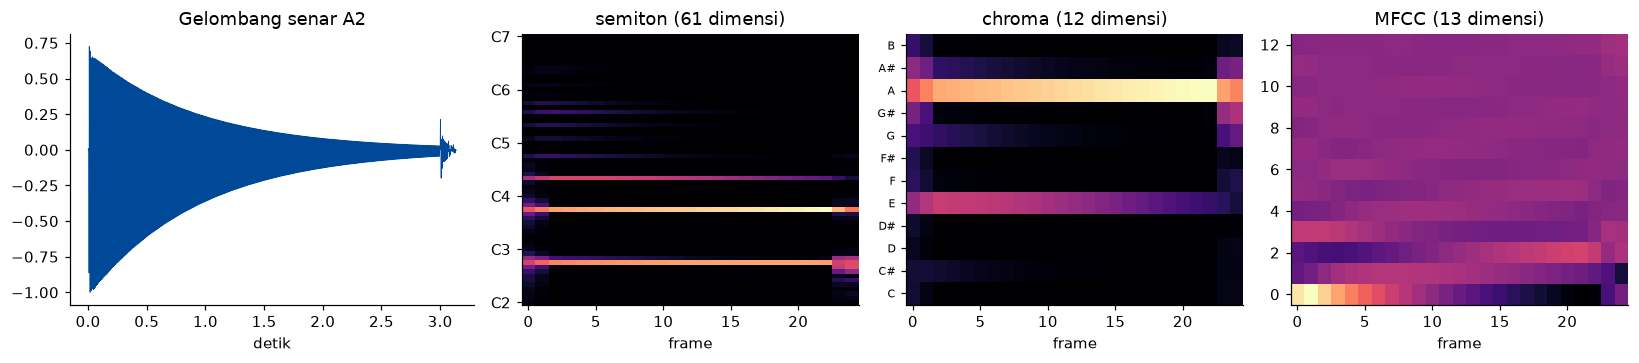

In [10]:
# Visualisasi: senar A2 (template) dalam ketiga representasi
x = audio_templ[45]
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4), gridspec_kw={"width_ratios": [1.2, 1, 1, 1]})
t = np.arange(len(x)) / SR
ax[0].plot(t, x, color=WARNA[0], lw=0.5); ax[0].set_title("Gelombang senar A2"); ax[0].set_xlabel("detik")
for a, (nama, f) in zip(ax[1:], FITUR.items()):
    F = f(x)
    a.imshow(F.T, origin="lower", aspect="auto", cmap="magma")
    a.set_title(f"{nama} ({F.shape[1]} dimensi)"); a.set_xlabel("frame")
ax[1].set_yticks([k for k, m in enumerate(MIDI_BIN) if m % 12 == 0])
ax[1].set_yticklabels([nama_nada(m) for m in MIDI_BIN if m % 12 == 0])
ax[2].set_yticks(range(12)); ax[2].set_yticklabels(NAMA_NADA, fontsize=7)
plt.tight_layout(); plt.show()

Pada fitur **semiton**, garis paling bawah yang terang adalah frekuensi dasar (A2), dan garis-garis di atasnya adalah harmonik (A3, E4, A4, …). Pada **chroma**, semua harmonik itu dilipat ke kelas nada A dan E. Pada **MFCC**, tidak ada garis nada yang jelas: yang tersimpan adalah bentuk garis besar spektrum.

In [11]:
# Mengapa chroma bermasalah untuk senar E2 vs E4? Bandingkan rata-rata vektornya.
for nama in ["semiton", "chroma", "MFCC"]:
    a, b = FITUR[nama](audio_templ[40]).mean(0), FITUR[nama](audio_templ[64]).mean(0)
    kos = a @ b / (np.linalg.norm(a) * np.linalg.norm(b))
    print(f"{nama:8s}: kemiripan kosinus rata-rata fitur E2 vs E4 = {kos:.3f}")

semiton : kemiripan kosinus rata-rata fitur E2 vs E4 = 0.104
chroma  : kemiripan kosinus rata-rata fitur E2 vs E4 = 0.876
MFCC    : kemiripan kosinus rata-rata fitur E2 vs E4 = 0.617


# BAGIAN 1. Tuner: senar mana yang dipetik?

## 1.1 Tiga cara mengukur jarak
Sama dengan notebook kelas:
1. **Euclid + padding nol**: deret yang lebih pendek diberi nol sampai panjangnya sama.
2. **Euclid + resampling**: kedua deret diregangkan ke panjang tetap (32 frame).
3. **DTW**: dinormalkan dengan $n+m$ agar tidak memihak deret yang pendek.

In [12]:
def euclid_pad(A, B):
    L = max(len(A), len(B))
    A2, B2 = np.zeros((L, A.shape[1])), np.zeros((L, B.shape[1]))
    A2[:len(A)], B2[:len(B)] = A, B
    return np.linalg.norm(A2 - B2) / L

def _regangkan(A, L=32):
    t0, t1 = np.linspace(0, 1, len(A)), np.linspace(0, 1, L)
    return np.stack([np.interp(t1, t0, A[:, d]) for d in range(A.shape[1])], axis=1)

def euclid_resample(A, B, L=32):
    return np.linalg.norm(_regangkan(A, L) - _regangkan(B, L)) / L

def dtw_norm(A, B, band=None):
    return dtw(A, B, band=band)[0] / (len(A) + len(B))

JARAK = {"Euclid padding": euclid_pad, "Euclid resampling": euclid_resample, "DTW": dtw_norm}

## 1.2 Baseline: cara kerja *tuner* sungguhan (YIN)
Tuner biasanya tidak memakai template, melainkan mengestimasi **frekuensi dasar** $f_0$ lalu membulatkannya ke nada terdekat. Kita pakai algoritma **YIN** (de Cheveigné & Kawahara, 2002) pada 1 detik pertama bunyi, lalu memilih senar dengan nada terdekat.

In [13]:
def yin_f0(x, fmin=60, fmax=1000, frame=2048, hop=512, ambang=0.15, maks_detik=1.0):
    tau_min, tau_max = int(SR / fmax), int(SR / fmin)
    batas = min(len(x), int(maks_detik * SR)) - frame - tau_max
    f0 = []
    for s in range(0, max(batas, 1), hop):
        w = x[s:s + frame + tau_max]
        if len(w) < frame + tau_max: break
        x0 = w[:frame]
        if np.sum(x0 ** 2) < 1e-6: continue
        acf = fftconvolve(w, x0[::-1], mode="valid")[: tau_max + 1]     # sum_j x0[j] * w[j+tau]
        e_geser = np.convolve(w ** 2, np.ones(frame), mode="valid")[: tau_max + 1]
        d = np.sum(x0 ** 2) + e_geser - 2 * acf                         # fungsi selisih
        d[0] = 0
        cmnd = d * np.arange(len(d)) / (np.cumsum(d) + 1e-12)            # dinormalkan rata-rata kumulatif
        cmnd[0] = 1
        kand = np.where(cmnd[tau_min:] < ambang)[0]
        if len(kand):
            tau = tau_min + kand[0]
            while tau + 1 < len(cmnd) and cmnd[tau + 1] < cmnd[tau]: tau += 1   # turun ke minimum lokal
        else:
            tau = tau_min + int(np.argmin(cmnd[tau_min:]))
        if 1 <= tau < len(cmnd) - 1:                                     # interpolasi parabola
            a, b, c = cmnd[tau - 1], cmnd[tau], cmnd[tau + 1]
            tau = tau + 0.5 * (a - c) / (a - 2 * b + c + 1e-12)
        f0.append(SR / tau)
    return float(np.median(f0)) if f0 else np.nan

def prediksi_yin(x):
    f = yin_f0(x)
    if not np.isfinite(f): return PITCH[0]
    return min(PITCH, key=lambda p: abs(p - hz_ke_midi(f)))

print("Uji YIN pada template:", {SENAR[p]: round(yin_f0(a), 1) for p, a in audio_templ.items()})

Uji YIN pada template: {'E2': 82.6, 'A2': 110.1, 'D3': 147.0, 'G3': 196.6, 'B3': 248.2, 'E4': 330.7}


## 1.3 Menjalankan klasifikasi dan menghitung akurasi

In [14]:
F_templ = {nf: [f(audio_templ[p]) for p in PITCH] for nf, f in FITUR.items()}
F_uji = {nf: [f(d["x"]) for d in data_uji] for nf, f in FITUR.items()}

def klasifikasi(nama_fitur, fungsi_jarak, **kw):
    pred = []
    for F in F_uji[nama_fitur]:
        jarak = [fungsi_jarak(T, F, **kw) for T in F_templ[nama_fitur]]
        pred.append(PITCH[int(np.argmin(jarak))])
    return np.array(pred)

hasil = pd.DataFrame([{k: d[k] for k in ["id", "pitch", "label", "instrumen", "velocity", "variasi"]} for d in data_uji])
waktu = {}
for nf in FITUR:
    for nj, fj in JARAK.items():
        t0 = time.time()
        hasil[f"{nf} | {nj}"] = klasifikasi(nf, fj)
        waktu[f"{nf} | {nj}"] = time.time() - t0
t0 = time.time()
hasil["YIN (baseline tuner)"] = [prediksi_yin(d["x"]) for d in data_uji]
waktu["YIN (baseline tuner)"] = time.time() - t0

METODE = [c for c in hasil.columns if "|" in c or c.startswith("YIN")]
print("Waktu komputasi (detik):", {k: round(v, 1) for k, v in waktu.items()})

Waktu komputasi (detik): {'semiton | Euclid padding': 0.0, 'semiton | Euclid resampling': 0.3, 'semiton | DTW': 0.3, 'chroma | Euclid padding': 0.0, 'chroma | Euclid resampling': 0.1, 'chroma | DTW': 0.2, 'MFCC | Euclid padding': 0.0, 'MFCC | Euclid resampling': 0.1, 'MFCC | DTW': 0.2, 'YIN (baseline tuner)': 0.8}


In [15]:
akurasi = pd.DataFrame({v: [(hasil.loc[hasil.variasi == v, m] == hasil.loc[hasil.variasi == v, "pitch"]).mean()
                            for m in METODE] for v in VARIASI}, index=METODE)
akurasi["rata-rata"] = [(hasil[m] == hasil.pitch).mean() for m in METODE]
display((akurasi * 100).round(1).style.format("{:.1f}%").background_gradient(cmap="Blues", vmin=0, vmax=100)
        if hasattr(akurasi, "style") and display is not print else (akurasi * 100).round(1))

,asli,derau,pendek,fals,rata-rata
semiton | Euclid padding,93.2%,93.2%,93.2%,93.2%,93.2%
semiton | Euclid resampling,90.9%,90.9%,90.9%,93.2%,91.5%
semiton | DTW,93.2%,93.2%,93.2%,93.2%,93.2%
chroma | Euclid padding,88.6%,88.6%,90.9%,88.6%,89.2%
chroma | Euclid resampling,88.6%,88.6%,88.6%,88.6%,88.6%
chroma | DTW,86.4%,86.4%,90.9%,86.4%,87.5%
MFCC | Euclid padding,34.1%,11.4%,11.4%,38.6%,23.9%
MFCC | Euclid resampling,29.5%,15.9%,31.8%,31.8%,27.3%
MFCC | DTW,29.5%,13.6%,45.5%,29.5%,29.5%
YIN (baseline tuner),100.0%,100.0%,100.0%,100.0%,100.0%


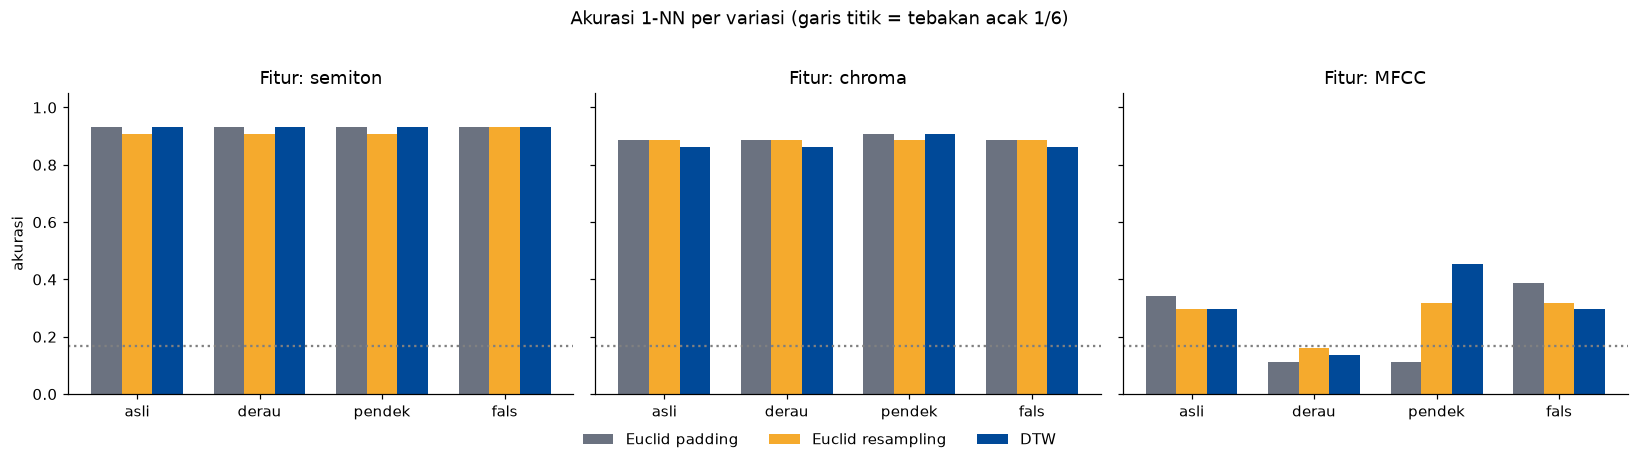

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, nf in zip(ax, FITUR):
    sub = akurasi.loc[[f"{nf} | {nj}" for nj in JARAK], VARIASI]
    lebar = 0.25
    for i, (nj, warna) in enumerate(zip(JARAK, [WARNA[4], WARNA[1], WARNA[0]])):
        a.bar(np.arange(len(VARIASI)) + (i - 1) * lebar, sub.iloc[i], lebar, label=nj, color=warna)
    a.axhline(1 / len(PITCH), ls=":", color="gray"); a.set_xticks(range(len(VARIASI))); a.set_xticklabels(VARIASI)
    a.set_title(f"Fitur: {nf}"); a.set_ylim(0, 1.05)
ax[0].set_ylabel("akurasi")
fig.legend(*ax[0].get_legend_handles_labels(), loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06), frameon=False)
plt.suptitle("Akurasi 1-NN per variasi (garis titik = tebakan acak 1/6)", y=1.02); plt.tight_layout(); plt.show()

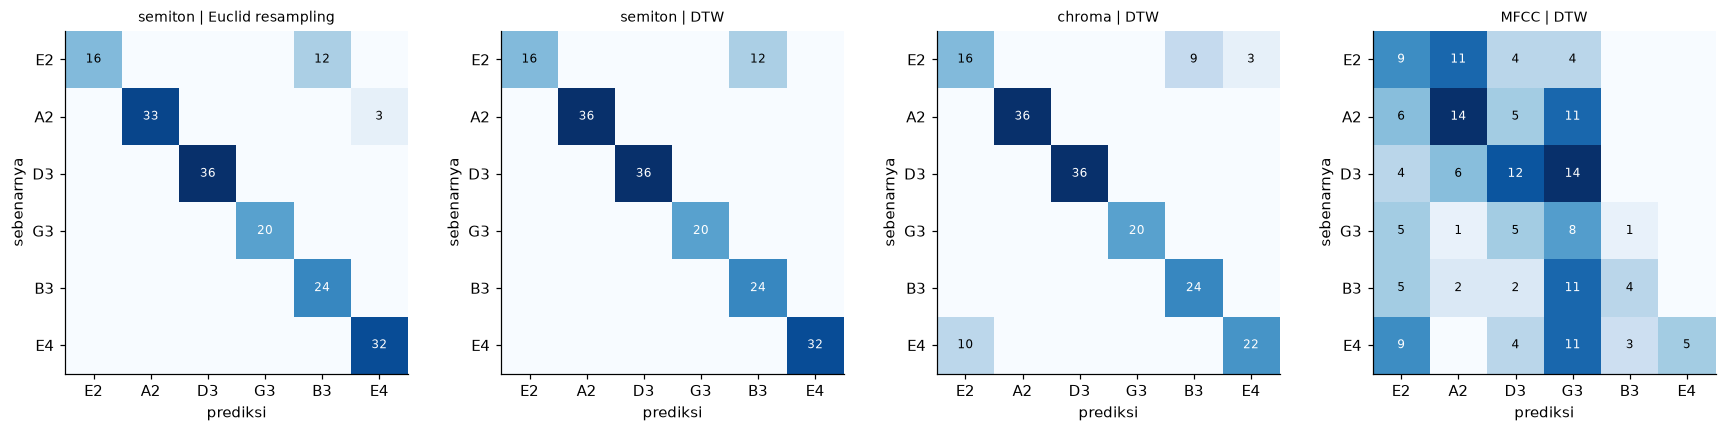

In [17]:
def matriks_konfusi(kolom, a, judul):
    K = pd.crosstab(hasil.label, hasil[kolom].map(SENAR)).reindex(index=LABEL, columns=LABEL, fill_value=0)
    a.imshow(K.values, cmap="Blues")
    for i in range(6):
        for j in range(6):
            if K.values[i, j]:
                a.text(j, i, K.values[i, j], ha="center", va="center",
                       color="white" if K.values[i, j] > K.values.max() / 2 else "black", fontsize=8)
    a.set_xticks(range(6)); a.set_xticklabels(LABEL); a.set_yticks(range(6)); a.set_yticklabels(LABEL)
    a.set_xlabel("prediksi"); a.set_ylabel("sebenarnya"); a.set_title(judul, fontsize=9)

kolom_k = ["semiton | Euclid resampling", "semiton | DTW", "chroma | DTW", "MFCC | DTW"]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, k in zip(ax, kolom_k): matriks_konfusi(k, a, k)
plt.tight_layout(); plt.show()

In [18]:
# Ringkasan otomatis untuk bahan tafsiran
terbaik = akurasi["rata-rata"].idxmax()
print(f"Metode terbaik secara rata-rata: {terbaik} ({akurasi.loc[terbaik, 'rata-rata']:.1%})")
for nf in FITUR:
    e, d = akurasi.loc[f"{nf} | Euclid resampling", "pendek"], akurasi.loc[f"{nf} | DTW", "pendek"]
    print(f"Variasi 'pendek', fitur {nf:7s}: Euclid resampling {e:.1%} vs DTW {d:.1%}")
kon = hasil[(hasil.label.isin(["E2", "E4"])) & (hasil["chroma | DTW"] != hasil.pitch)]
print(f"Kesalahan chroma|DTW pada senar E2/E4: {len(kon)}, "
      f"di antaranya tertukar E2<->E4: {(kon['chroma | DTW'].isin([40, 64])).sum()}")
salah = hasil[hasil["semiton | DTW"] != hasil.pitch]
print(f"\nContoh kesalahan semiton|DTW ({len(salah)} dari {len(hasil)}):")
for _, r in salah.head(8).iterrows():
    print(f"  {r.instrumen:24s} vel {r.velocity:3d} {r.variasi:7s}: {r.label} -> {SENAR[r['semiton | DTW']]}")

Metode terbaik secara rata-rata: YIN (baseline tuner) (100.0%)
Variasi 'pendek', fitur semiton: Euclid resampling 90.9% vs DTW 93.2%
Variasi 'pendek', fitur chroma : Euclid resampling 88.6% vs DTW 90.9%
Variasi 'pendek', fitur MFCC   : Euclid resampling 31.8% vs DTW 45.5%
Kesalahan chroma|DTW pada senar E2/E4: 22, di antaranya tertukar E2<->E4: 13

Contoh kesalahan semiton|DTW (12 dari 176):
  guitar_acoustic_015      vel  50 asli   : E2 -> B3
  guitar_acoustic_015      vel  50 derau  : E2 -> B3
  guitar_acoustic_015      vel  50 pendek : E2 -> B3
  guitar_acoustic_015      vel  50 fals   : E2 -> B3
  guitar_acoustic_015      vel  75 asli   : E2 -> B3
  guitar_acoustic_015      vel  75 derau  : E2 -> B3
  guitar_acoustic_015      vel  75 pendek : E2 -> B3
  guitar_acoustic_015      vel  75 fals   : E2 -> B3


## 1.4 Analisis akurasi secara statistik
Akurasi saja belum cukup untuk laporan. Sel-sel berikut menambahkan:
- **Selang kepercayaan 95% (Wilson)** untuk akurasi. Data uji hanya ratusan bunyi, jadi selisih beberapa persen belum tentu bermakna.
- **Presisi, recall, dan F1 per kelas**. Akurasi total bisa menutupi kelas yang sering gagal. F1 makro = rata-rata F1 semua kelas.
- **Uji McNemar** untuk membandingkan dua metode pada data uji yang sama. Yang dihitung hanya bunyi yang ditebak benar oleh satu metode tetapi salah oleh metode lain ($b$ dan $c$). Di bawah $H_0$ (kedua metode sama baik), $b \sim \text{Binomial}(b+c,\ 0{,}5)$. Kita pakai versi eksak (uji binomial).

In [19]:
def wilson(k, n, z=1.96):
    # selang kepercayaan Wilson untuk proporsi k/n
    if n == 0: return (np.nan, np.nan)
    p = k / n; den = 1 + z ** 2 / n
    pusat = (p + z ** 2 / (2 * n)) / den
    lebar = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return pusat - lebar, pusat + lebar

def metrik_per_kelas(y, yhat, kelas, nama):
    baris = []
    for k, nm in zip(kelas, nama):
        tp = np.sum((yhat == k) & (y == k)); fp = np.sum((yhat == k) & (y != k)); fn = np.sum((yhat != k) & (y == k))
        pre = tp / (tp + fp) if tp + fp else 0.0; rec = tp / (tp + fn) if tp + fn else 0.0
        baris.append({"kelas": nm, "presisi": pre, "recall": rec,
                      "F1": 2 * pre * rec / (pre + rec) if pre + rec else 0.0, "jumlah": int(np.sum(y == k))})
    return pd.DataFrame(baris).set_index("kelas")

def tabel_akurasi(y, prediksi, kelas, nama):
    baris = []
    for m, yhat in prediksi.items():
        k, n = int(np.sum(yhat == y)), len(y); lo, hi = wilson(k, n)
        baris.append({"metode": m, "akurasi": k / n, "CI 95% bawah": lo, "CI 95% atas": hi,
                      "F1 makro": metrik_per_kelas(y, yhat, kelas, nama).F1.mean(), "benar / total": f"{k} / {n}"})
    return pd.DataFrame(baris).set_index("metode").sort_values("akurasi", ascending=False)

def mcnemar(y, a, b):
    # b_ = A benar & B salah ; c_ = A salah & B benar ; uji binomial eksak dua sisi
    b_, c_ = int(np.sum((a == y) & (b != y))), int(np.sum((a != y) & (b == y)))
    p = binomtest(min(b_, c_), b_ + c_, 0.5).pvalue if b_ + c_ else 1.0
    return b_, c_, p

def tabel_mcnemar(y, prediksi, pasangan):
    baris = []
    for a, b in pasangan:
        b_, c_, p = mcnemar(y, prediksi[a], prediksi[b])
        baris.append({"metode A": a, "metode B": b, "A benar, B salah": b_, "A salah, B benar": c_,
                      "p-value": p, "kesimpulan (α = 5%)": ("A lebih baik" if b_ > c_ else "B lebih baik")
                      if p < 0.05 else "tidak berbeda nyata"})
    return pd.DataFrame(baris)

fmt_persen = {"akurasi": "{:.1%}", "CI 95% bawah": "{:.1%}", "CI 95% atas": "{:.1%}", "F1 makro": "{:.3f}"}
def tampil(df, fmt=None):
    display(df.style.format(fmt) if (fmt and display is not print) else df)

y1 = hasil.pitch.to_numpy()
pred1 = {m: hasil[m].to_numpy() for m in METODE}
akurasi1 = tabel_akurasi(y1, pred1, PITCH, LABEL)
print("Akurasi semua metode (semua variasi digabung):")
tampil(akurasi1, fmt_persen)

Akurasi semua metode (semua variasi digabung):


,akurasi,CI 95% bawah,CI 95% atas,F1 makro,benar / total
metode,,,,,
YIN (baseline tuner),100.0%,97.9%,100.0%,1.000,176 / 176
semiton | Euclid padding,93.2%,88.5%,96.1%,0.921,164 / 176
semiton | DTW,93.2%,88.5%,96.1%,0.921,164 / 176
semiton | Euclid resampling,91.5%,86.4%,94.8%,0.907,161 / 176
chroma | Euclid padding,89.2%,83.8%,93.0%,0.887,157 / 176
chroma | Euclid resampling,88.6%,83.1%,92.5%,0.882,156 / 176
chroma | DTW,87.5%,81.8%,91.6%,0.868,154 / 176
MFCC | DTW,29.5%,23.3%,36.7%,0.291,52 / 176
MFCC | Euclid resampling,27.3%,21.2%,34.3%,0.257,48 / 176


In [20]:
# Presisi, recall, F1 per senar untuk metode utama dan pembandingnya
for m in ["semiton | DTW", "chroma | DTW", "YIN (baseline tuner)"]:
    print(f"\n{m}")
    tampil(metrik_per_kelas(y1, pred1[m], PITCH, LABEL), {"presisi": "{:.3f}", "recall": "{:.3f}", "F1": "{:.3f}"})


semiton | DTW


,presisi,recall,F1,jumlah
kelas,,,,
E2,1.000,0.571,0.727,28
A2,1.000,1.000,1.000,36
D3,1.000,1.000,1.000,36
G3,1.000,1.000,1.000,20
B3,0.667,1.000,0.800,24
E4,1.000,1.000,1.000,32



chroma | DTW


,presisi,recall,F1,jumlah
kelas,,,,
E2,0.615,0.571,0.593,28
A2,1.000,1.000,1.000,36
D3,1.000,1.000,1.000,36
G3,1.000,1.000,1.000,20
B3,0.727,1.000,0.842,24
E4,0.880,0.688,0.772,32



YIN (baseline tuner)


,presisi,recall,F1,jumlah
kelas,,,,
E2,1.000,1.000,1.000,28
A2,1.000,1.000,1.000,36
D3,1.000,1.000,1.000,36
G3,1.000,1.000,1.000,20
B3,1.000,1.000,1.000,24
E4,1.000,1.000,1.000,32


In [21]:
# Uji McNemar: apakah perbedaan akurasi bermakna secara statistik?
pasangan1 = [("semiton | DTW", "semiton | Euclid resampling"), ("semiton | DTW", "semiton | Euclid padding"),
             ("semiton | DTW", "chroma | DTW"), ("semiton | DTW", "MFCC | DTW"), ("semiton | DTW", "YIN (baseline tuner)")]
print("Semua variasi:")
tampil(tabel_mcnemar(y1, pred1, pasangan1), {"p-value": "{:.4f}"})
pendek = (hasil.variasi == "pendek").to_numpy()
print("Hanya variasi 'pendek' (panjang uji jauh berbeda dari template):")
tampil(tabel_mcnemar(y1[pendek], {m: v[pendek] for m, v in pred1.items()}, pasangan1[:2]), {"p-value": "{:.4f}"})

Semua variasi:


,metode A,metode B,"A benar, B salah","A salah, B benar",p-value,kesimpulan (α = 5%)
0,semiton | DTW,semiton | Euclid resampling,3,0,0.2500,tidak berbeda nyata
1,semiton | DTW,semiton | Euclid padding,0,0,1.0000,tidak berbeda nyata
2,semiton | DTW,chroma | DTW,13,3,0.0213,A lebih baik
3,semiton | DTW,MFCC | DTW,115,3,0.0000,A lebih baik
4,semiton | DTW,YIN (baseline tuner),0,12,0.0005,B lebih baik


Hanya variasi 'pendek' (panjang uji jauh berbeda dari template):


,metode A,metode B,"A benar, B salah","A salah, B benar",p-value,kesimpulan (α = 5%)
0,semiton | DTW,semiton | Euclid resampling,1,0,1.0000,tidak berbeda nyata
1,semiton | DTW,semiton | Euclid padding,0,0,1.0000,tidak berbeda nyata


**Pertanyaan untuk tafsiran** (jawab berdasarkan angka di atas pada data NSynth):
1. Fitur mana yang paling cocok untuk mengenali nada? Apakah MFCC memang jauh tertinggal, sesuai penjelasan bahwa MFCC menangkap warna suara?
2. Apakah chroma sering menukar **E2 ↔ E4**? Mengapa?
3. Pada variasi **pendek**, seberapa besar keunggulan DTW dibanding Euclid? (Panjang template ±3–4 detik, panjang uji hanya 0,8 detik.)
4. Pada variasi **fals ±35 cent**, apakah semua metode tetap mengenali senarnya? Apa yang terjadi bila geserannya mendekati 50 cent (setengah semitone)?
5. Bagaimana DTW dibanding *baseline* YIN? Kapan DTW berguna, dan kapan metode sederhana sudah cukup?
6. Apakah selang kepercayaan metode terbaik dan pembandingnya tumpang tindih? Apa kata uji McNemar?
7. Senar mana yang F1-nya paling rendah? Apakah senar E2 (frekuensi paling rendah) lebih sulit?

## 1.5 Melihat jalur warping: template vs bunyi pendek

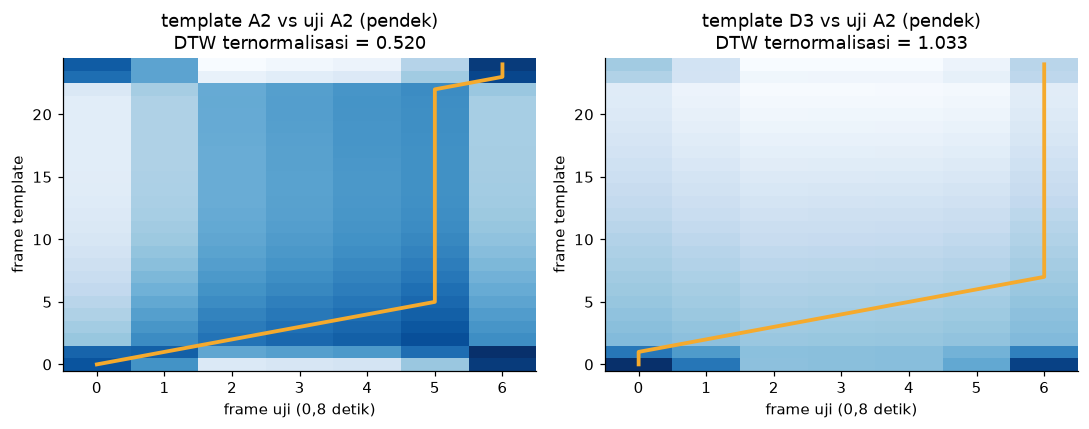

In [22]:
d0 = next(d for d in data_uji if d["pitch"] == 45 and d["variasi"] == "pendek")
F = fitur_semiton(d0["x"])
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, p in zip(ax, [45, 50]):
    T = F_templ["semiton"][PITCH.index(p)]
    jarak, _, jalur = dtw(T, F)
    C = np.sqrt(((T[:, None] - F[None]) ** 2).sum(-1))
    a.imshow(C, origin="lower", aspect="auto", cmap="Blues_r")
    a.plot(jalur[:, 1], jalur[:, 0], color=WARNA[1], lw=2.5)
    a.set_title(f"template {SENAR[p]} vs uji A2 (pendek)\nDTW ternormalisasi = {jarak / (len(T) + len(F)):.3f}")
    a.set_xlabel("frame uji (0,8 detik)"); a.set_ylabel("frame template")
plt.tight_layout(); plt.show()

Uji hanya punya beberapa frame, sedangkan template puluhan frame. Euclid dengan padding membandingkan bagian peluruhan template dengan nol, dan resampling meregangkan 0,8 detik menjadi seolah 4 detik. DTW memasangkan frame uji dengan bagian template yang paling cocok, lalu "menghabiskan" sisa template dengan langkah vertikal. Jalur ke template yang benar melewati daerah gelap (biaya kecil).

## 1.6 Fitur tuner: berapa *cent* lagi?

Setelah senarnya dikenali, tuner menampilkan selisih terhadap nada tepat:

$$\text{cent} = 1200 \cdot \log_2\!\left(\frac{f_0}{f_\text{acuan}}\right)$$

100 cent = 1 semitone. Selisih di bawah ±5 cent biasanya dianggap sudah pas. Di sini senar ditentukan oleh **DTW (fitur semiton)**, dan *cent* dihitung dari $f_0$ hasil YIN.

In [23]:
def tuner(x, verbose=True):
    F = fitur_semiton(x)
    p = PITCH[int(np.argmin([dtw_norm(T, F) for T in F_templ["semiton"]]))]
    f0 = yin_f0(x)
    # bila YIN salah oktaf, lipat f0 ke oktaf senar yang dikenali DTW
    if np.isfinite(f0):
        f0 = f0 * 2.0 ** np.round(np.log2(midi_ke_hz(p) / f0))
    cent = 1200 * np.log2(f0 / midi_ke_hz(p)) if np.isfinite(f0) else np.nan
    if not np.isfinite(cent): status = "f0 tidak terdeteksi"
    elif abs(cent) < 5:       status = "PAS"
    elif cent < 0:            status = "terlalu rendah -> kencangkan senar"
    else:                     status = "terlalu tinggi -> kendurkan senar"
    if verbose:
        print(f"Senar {SENAR[p]} ({midi_ke_hz(p):6.1f} Hz) | terdeteksi {f0:6.1f} Hz | {cent:+6.1f} cent | {status}")
    return p, cent

contoh = [d for d in data_uji if d["id"] == uji.index[uji.pitch == 50][0]]
for d in contoh:
    print(f"[{d['variasi']:6s}] ", end=""); tuner(d["x"])

# akurasi cent pada variasi 'fals' (nilai sebenarnya +-35 cent, dan rekaman asli dianggap 0)
c_asli = np.array([tuner(d["x"], verbose=False)[1] for d in data_uji if d["variasi"] == "asli"])
c_fals = np.array([abs(tuner(d["x"], verbose=False)[1]) for d in data_uji if d["variasi"] == "fals"])
print(f"\nMedian |cent| rekaman asli : {np.nanmedian(np.abs(c_asli)):.1f} (idealnya ~0)")
print(f"Median |cent| variasi fals : {np.nanmedian(c_fals):.1f} (idealnya ~35)")

[asli  ] Senar D3 ( 146.8 Hz) | terdeteksi  147.3 Hz |   +5.0 cent | terlalu tinggi -> kendurkan senar
[derau ] Senar D3 ( 146.8 Hz) | terdeteksi  147.3 Hz |   +5.3 cent | terlalu tinggi -> kendurkan senar
[pendek] Senar D3 ( 146.8 Hz) | terdeteksi  147.3 Hz |   +5.0 cent | terlalu tinggi -> kendurkan senar
[fals  ] Senar D3 ( 146.8 Hz) | terdeteksi  150.3 Hz |  +40.0 cent | terlalu tinggi -> kendurkan senar

Median |cent| rekaman asli : 5.7 (idealnya ~0)
Median |cent| variasi fals : 34.3 (idealnya ~35)


## 1.7 Jendela Sakoe–Chiba
Seperti di notebook kelas, kita lihat akurasi dan waktu komputasi DTW (fitur semiton) untuk beberapa lebar jendela.

In [24]:
baris = []
for band in [None, 10, 5, 2, 1]:
    t0 = time.time(); pred = klasifikasi("semiton", dtw_norm, band=band); dt = time.time() - t0
    baris.append({"jendela (frame)": "tanpa" if band is None else band,
                  "akurasi": f"{(pred == hasil.pitch.to_numpy()).mean():.1%}",
                  "akurasi 'pendek'": f"{(pred[hasil.variasi == 'pendek'] == hasil.pitch[hasil.variasi == 'pendek']).mean():.1%}",
                  "waktu (detik)": round(dt, 2)})
display(pd.DataFrame(baris))

,jendela (frame),akurasi,akurasi 'pendek',waktu (detik)
0,tanpa,93.2%,93.2%,0.37
1,10,93.2%,93.2%,0.24
2,5,93.2%,93.2%,0.18
3,2,92.6%,90.9%,0.15
4,1,92.6%,90.9%,0.13


Perhatikan kolom *pendek*: bila panjang dua deret sangat berbeda, jendela yang sempit memaksa jalur mengikuti diagonal yang "diregangkan", sehingga DTW kembali mirip Euclid resampling.

# BAGIAN 2. Cek chord: chord apa yang digenjreng, dan apakah sudah benar?

Satu senar menghasilkan satu nada. Satu genjrengan chord menghasilkan **4–6 nada sekaligus**, dan senar-senarnya berbunyi **berurutan** dalam beberapa puluh milidetik (dari bawah ke atas untuk genjrengan turun, atau sebaliknya). Karena itu ada beberapa hal yang berubah dari Bagian 1:

- **Fitur utama: chroma.** Yang menentukan chord adalah *kumpulan nama nada*. C mayor = C, E, G, di oktaf mana pun. Sifat chroma yang di Bagian 1 menjadi kelemahan (tidak membedakan oktaf) di sini justru menjadi kelebihan.
- **Baseline: template chord biner.** YIN tidak bisa dipakai karena hanya untuk satu nada. Baseline klasik pengenalan chord adalah mencocokkan rata-rata chroma dengan pola biner (C mayor = 1 di C, E, G; 0 di nada lain).
- **Peran DTW lebih besar.** Arah dan kecepatan genjrengan berbeda-beda, sehingga urutan munculnya nada di awal bunyi juga berbeda.

**Delapan chord terbuka** yang dipakai (nada dari senar 6 ke senar 1; `x` = senar tidak dibunyikan):

| Chord | Posisi jari | Nada | Kelas nada |
|---|---|---|---|
| C | x 3 2 0 1 0 | C3 E3 G3 C4 E4 | C E G |
| D | x x 0 2 3 2 | D3 A3 D4 F#4 | D F# A |
| E | 0 2 2 1 0 0 | E2 B2 E3 G#3 B3 E4 | E G# B |
| G | 3 2 0 0 0 3 | G2 B2 D3 G3 B3 G4 | G B D |
| A | x 0 2 2 2 0 | A2 E3 A3 C#4 E4 | A C# E |
| Am | x 0 2 2 1 0 | A2 E3 A3 C4 E4 | A C E |
| Em | 0 2 2 0 0 0 | E2 B2 E3 G3 B3 E4 | E G B |
| Dm | x x 0 2 3 1 | D3 A3 D4 F4 | D F A |

Pasangan **A/Am, E/Em, dan D/Dm** hanya berbeda **satu nada** (setengah nada). Pasangan inilah ujian terberat bagi setiap metode.

Bagian ini menjawab dua pertanyaan:
1. **Klasifikasi** (2.2): chord apa ini? Sama seperti Bagian 1: 1-NN ke 8 template.
2. **Verifikasi** (2.4): "saya mau main G, sudah benar belum?" Jarak ke template chord yang dituju dibandingkan dengan ambang batas. Dievaluasi dengan ROC-AUC, sensitivitas, dan spesifisitas.

## 2.1 Merakit genjrengan dari nada NSynth

Untuk setiap chord, nada-nada gitar dari **instrumen yang sama** dijumlahkan dengan jeda antarsenar:

- **Template**: satu gitar di pool template (valid), genjrengan turun, jeda 25 ms, velocity ≈ 75.
- **Data uji (chord benar)**: semua gitar di pool uji (test), dua tingkat velocity, empat variasi:

| Variasi | Arti |
|---|---|
| `turun` | genjrengan turun, jeda acak 10–40 ms per senar |
| `naik` | genjrengan naik (urutan senar terbalik), jeda 10–40 ms |
| `lambat` | genjrengan turun pelan, jeda 70–100 ms (mendekati petikan arpeggio) |
| `derau` | genjrengan turun + derau putih SNR 15 dB |

- **Data uji (chord salah)**, khusus untuk verifikasi:

| Jenis kesalahan | Cara membuat | Contoh nyata |
|---|---|---|
| `nada salah` | satu senar digeser ±1 semitone ke nada di luar chord | jari salah fret atau salah senar |
| `senar mati` | satu senar dihilangkan | jari menempel ke senar sebelah sehingga senar tidak berbunyi |

Kekuatan tiap senar juga diacak ±20% agar genjrengan tidak terlalu seragam.

In [25]:
_cache_audio = {}
def muat_cache(path):
    if path not in _cache_audio:
        _cache_audio[path] = muat(path)
    return _cache_audio[path]

def ambil_nada(meta, inst, pitch, vel):
    m = meta[(meta.instrument_str == inst) & (meta.pitch == pitch)]
    if m.empty: return None
    return muat_cache(m.path.iloc[int(np.argmin(np.abs(m.velocity.to_numpy() - vel)))])

def genjreng(nada, jeda, arah="turun", durasi=3.0, rng=None, acak_amp=0.0):
    urut = list(nada) if arah == "turun" else list(nada)[::-1]
    L = int(durasi * SR); y = np.zeros(L)
    for k, x in enumerate(urut):
        s = int(round(k * jeda * SR))
        if s >= L: break
        g = 1.0 + (rng.uniform(-acak_amp, acak_amp) if rng is not None and acak_amp else 0.0)
        seg = x[: L - s]; y[s:s + len(seg)] += g * seg
    return y / (np.abs(y).max() + 1e-9)

def rakit(meta, inst, pitches, vel, jeda, arah="turun", rng=None, acak_amp=0.0):
    nada = [ambil_nada(meta, inst, p, vel) for p in pitches]
    return None if any(n is None for n in nada) else genjreng(nada, jeda, arah, rng=rng, acak_amp=acak_amp)

def punya(meta, inst, pitches):
    return set(pitches) <= set(meta.pitch[meta.instrument_str == inst])

# --- template: satu gitar (utamakan akustik) yang punya semua nada untuk 8 chord
def pilih_gitar_template(meta):
    urut = (meta.drop_duplicates("instrument_str")
            .assign(bukan_akustik=lambda d: (d.instrument_source_str != "acoustic").astype(int))
            .sort_values(["bukan_akustik", "instrument_str"]).instrument_str)
    for inst in urut:
        if all(punya(meta, inst, CHORD[c]) for c in NAMA_CHORD):
            return {c: inst for c in NAMA_CHORD}
    print("Peringatan: tidak ada satu gitar yang punya semua chord; template diambil dari gitar berbeda per chord.")
    hasil_pilih = {}
    for c in NAMA_CHORD:
        cocok = [i for i in urut if punya(meta, i, CHORD[c])]
        assert cocok, f"Tidak ada gitar di pool template yang punya semua nada chord {c}"
        hasil_pilih[c] = cocok[0]
    return hasil_pilih

inst_templ2 = pilih_gitar_template(meta_v_semua)
audio_templ2 = {c: pangkas_sunyi(rakit(meta_v_semua, inst_templ2[c], CHORD[c], 75, 0.025)) for c in NAMA_CHORD}
print("Gitar template:", sorted(set(inst_templ2.values())))

Gitar template: ['guitar_acoustic_010']


In [26]:
VEL_UJI = [50, 100]          # dua tingkat kekuatan petik per gitar uji
VARIASI2 = ["turun", "naik", "lambat", "derau"]
rng2 = np.random.default_rng(2026)
pc = lambda pitches: {p % 12 for p in pitches}

def tambah_derau(x, rng, snr=15):
    return x + rng.normal(0, np.sqrt(np.mean(x ** 2) / 10 ** (snr / 10)), len(x))

data2, salah2 = [], []                       # chord benar (klasifikasi + verifikasi) dan chord salah (verifikasi)
inst_uji2 = sorted(meta_t_semua.instrument_str.unique())
for inst in inst_uji2:
    for vel in VEL_UJI:
        for c in NAMA_CHORD:
            if not punya(meta_t_semua, inst, CHORD[c]): continue
            info = {"chord": c, "instrumen": inst, "velocity": vel}
            for v in VARIASI2:
                jeda = rng2.uniform(0.07, 0.10) if v == "lambat" else rng2.uniform(0.01, 0.04)
                x = rakit(meta_t_semua, inst, CHORD[c], vel, jeda, "naik" if v == "naik" else "turun", rng2, 0.2)
                if v == "derau": x = tambah_derau(x, rng2)
                data2.append({**info, "variasi": v, "x": pangkas_sunyi(x)})
            # chord salah: 2x nada salah + 2x senar mati
            senar = list(CHORD[c])
            for jenis in ["nada salah", "nada salah", "senar mati", "senar mati"]:
                for _ in range(20):                                   # cari kesalahan yang nadanya tersedia
                    i = int(rng2.integers(len(senar))); p_baru = senar.copy()
                    if jenis == "nada salah":
                        geser = senar[i] + int(rng2.choice([-1, 1]))
                        if geser % 12 in pc(senar) or geser not in NADA_DIBUTUHKAN: continue
                        p_baru[i] = geser
                    else:
                        del p_baru[i]
                    x = rakit(meta_t_semua, inst, p_baru, vel, rng2.uniform(0.01, 0.04),
                              str(rng2.choice(["turun", "naik"])), rng2, 0.2)
                    if x is None: continue
                    salah2.append({**info, "variasi": jenis, "nada": p_baru, "x": pangkas_sunyi(x)}); break

print(f"Gitar uji: {len(inst_uji2)} | chord benar: {len(data2)} bunyi | chord salah: {len(salah2)} bunyi")
display(pd.DataFrame(data2).groupby(["chord", "variasi"]).size().unstack().reindex(NAMA_CHORD))

Gitar uji: 7 | chord benar: 136 bunyi | chord salah: 136 bunyi


variasi,derau,lambat,naik,turun
chord,,,,
C,6.0,6.0,6.0,6.0
D,4.0,4.0,4.0,4.0
E,NaN,NaN,NaN,NaN
G,2.0,2.0,2.0,2.0
A,10.0,10.0,10.0,10.0
Am,8.0,8.0,8.0,8.0
Em,NaN,NaN,NaN,NaN
Dm,4.0,4.0,4.0,4.0


In [27]:
# Dengarkan template G dan satu genjrengan G lambat dari gitar uji (hanya di Jupyter)
if Audio is not None:
    display(Audio(audio_templ2["G"], rate=SR))
    display(Audio(next(d["x"] for d in data2 if d["chord"] == "G" and d["variasi"] == "lambat"), rate=SR))

## 2.2 Klasifikasi chord: 1-NN ke 8 template
Fitur dan jarak sama persis dengan Bagian 1. Baseline-nya adalah **template chord biner**: rata-rata chroma pada 1,5 detik pertama dibandingkan (kemiripan kosinus) dengan pola 12 nada setiap chord, lalu dipilih yang paling mirip.

In [28]:
POLA_BINER = {c: np.isin(np.arange(12), list(pc(CHORD[c]))).astype(float) for c in NAMA_CHORD}
N_AWAL = int(1.5 * SR / HOP)                                  # jumlah frame dalam 1,5 detik

def kos(a, b): return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))

def prediksi_biner(F_chroma):
    v = F_chroma[:N_AWAL].mean(0)
    return NAMA_CHORD[int(np.argmax([kos(v, POLA_BINER[c]) for c in NAMA_CHORD]))]

F_templ2 = {nf: [f(audio_templ2[c]) for c in NAMA_CHORD] for nf, f in FITUR.items()}
F_uji2 = {nf: [f(d["x"]) for d in data2] for nf, f in FITUR.items()}

hasil2 = pd.DataFrame([{k: d[k] for k in ["chord", "instrumen", "velocity", "variasi"]} for d in data2])
waktu2 = {}
for nf in FITUR:
    for nj, fj in JARAK.items():
        t0 = time.time()
        hasil2[f"{nf} | {nj}"] = [NAMA_CHORD[int(np.argmin([fj(T, F) for T in F_templ2[nf]]))] for F in F_uji2[nf]]
        waktu2[f"{nf} | {nj}"] = time.time() - t0
hasil2["template biner (baseline)"] = [prediksi_biner(F) for F in F_uji2["chroma"]]
METODE2 = [c for c in hasil2.columns if "|" in c or c.startswith("template")]
print("Waktu komputasi (detik):", {k: round(v, 1) for k, v in waktu2.items()})

akurasi2_var = pd.DataFrame({v: [(hasil2.loc[hasil2.variasi == v, m] == hasil2.loc[hasil2.variasi == v, "chord"]).mean()
                                 for m in METODE2] for v in VARIASI2}, index=METODE2)
akurasi2_var["rata-rata"] = [(hasil2[m] == hasil2.chord).mean() for m in METODE2]
display((akurasi2_var * 100).round(1).style.format("{:.1f}%").background_gradient(cmap="Blues", vmin=0, vmax=100)
        if display is not print else (akurasi2_var * 100).round(1))

Waktu komputasi (detik): {'semiton | Euclid padding': 0.0, 'semiton | Euclid resampling': 0.3, 'semiton | DTW': 0.3, 'chroma | Euclid padding': 0.0, 'chroma | Euclid resampling': 0.1, 'chroma | DTW': 0.3, 'MFCC | Euclid padding': 0.0, 'MFCC | Euclid resampling': 0.2, 'MFCC | DTW': 0.3}


,turun,naik,lambat,derau,rata-rata
semiton | Euclid padding,100.0%,100.0%,100.0%,100.0%,100.0%
semiton | Euclid resampling,100.0%,100.0%,100.0%,100.0%,100.0%
semiton | DTW,100.0%,100.0%,100.0%,100.0%,100.0%
chroma | Euclid padding,97.1%,97.1%,100.0%,97.1%,97.8%
chroma | Euclid resampling,97.1%,97.1%,100.0%,97.1%,97.8%
chroma | DTW,97.1%,97.1%,100.0%,97.1%,97.8%
MFCC | Euclid padding,20.6%,23.5%,26.5%,17.6%,22.1%
MFCC | Euclid resampling,20.6%,23.5%,26.5%,17.6%,22.1%
MFCC | DTW,29.4%,26.5%,29.4%,17.6%,25.7%
template biner (baseline),94.1%,94.1%,94.1%,97.1%,94.9%


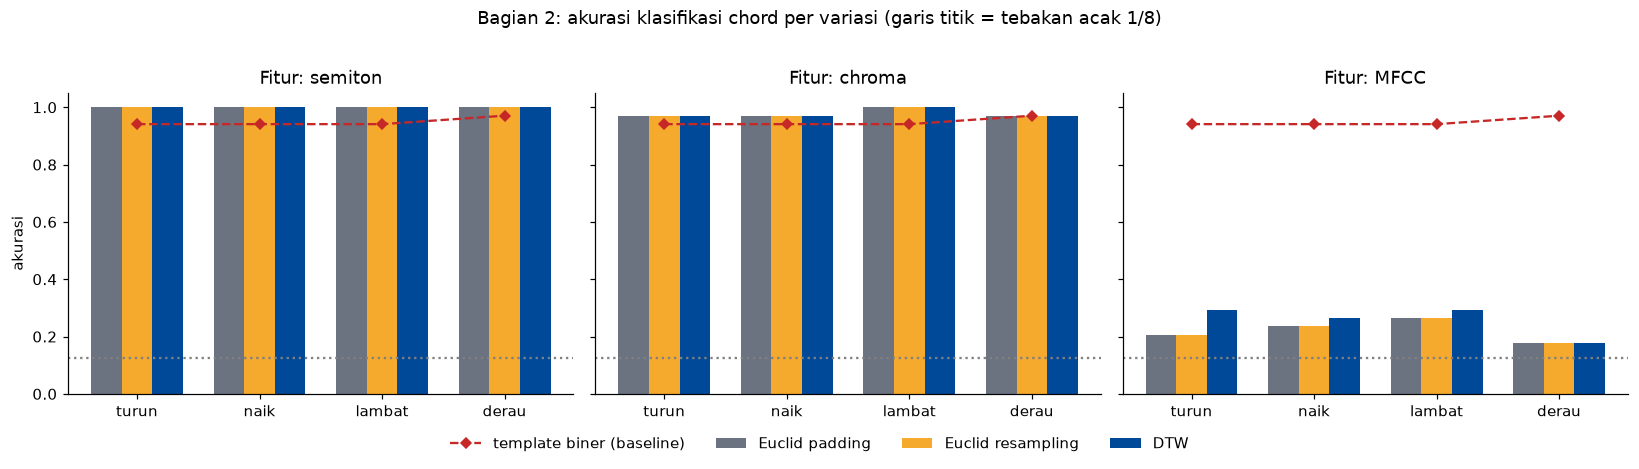

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, nf in zip(ax, FITUR):
    sub = akurasi2_var.loc[[f"{nf} | {nj}" for nj in JARAK], VARIASI2]
    for i, (nj, warna) in enumerate(zip(JARAK, [WARNA[4], WARNA[1], WARNA[0]])):
        a.bar(np.arange(len(VARIASI2)) + (i - 1) * 0.25, sub.iloc[i], 0.25, label=nj, color=warna)
    a.plot(range(len(VARIASI2)), akurasi2_var.loc["template biner (baseline)", VARIASI2], "D--", color=WARNA[3],
           label="template biner (baseline)", ms=5)
    a.axhline(1 / len(NAMA_CHORD), ls=":", color="gray"); a.set_xticks(range(len(VARIASI2))); a.set_xticklabels(VARIASI2)
    a.set_title(f"Fitur: {nf}"); a.set_ylim(0, 1.05)
ax[0].set_ylabel("akurasi")
fig.legend(*ax[0].get_legend_handles_labels(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.07), frameon=False)
plt.suptitle("Bagian 2: akurasi klasifikasi chord per variasi (garis titik = tebakan acak 1/8)", y=1.02)
plt.tight_layout(); plt.show()

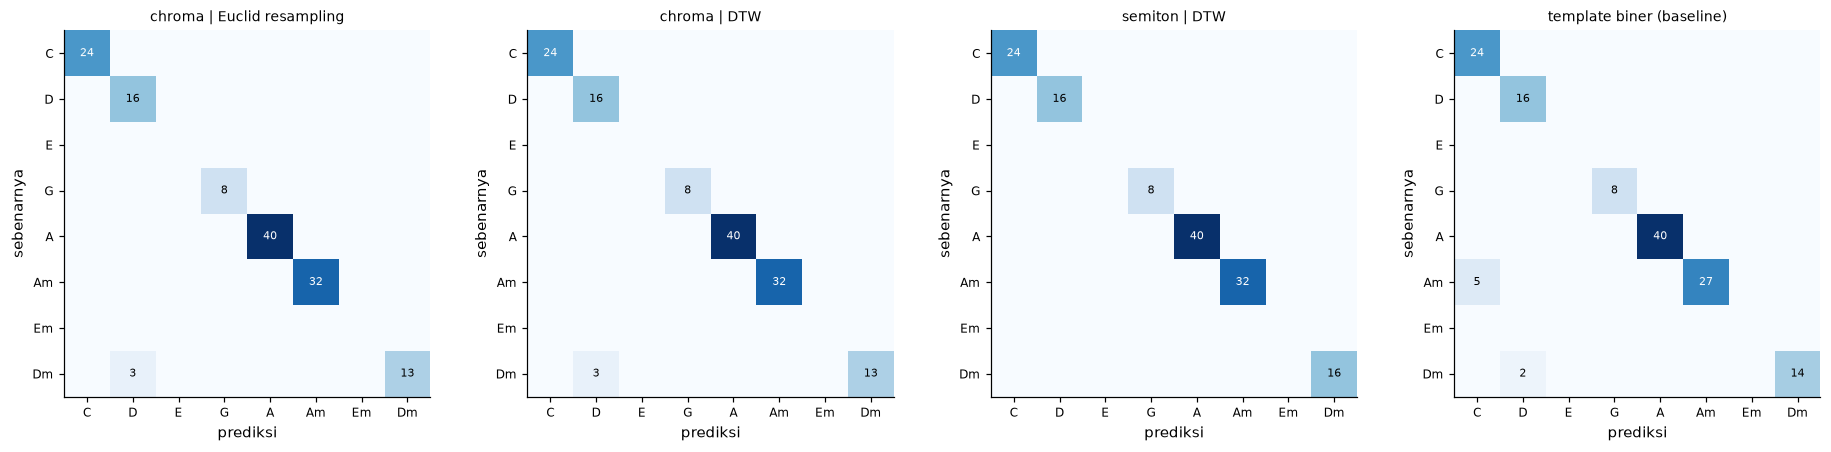

chroma | DTW                 tertukar pada pasangan mayor/minor -> A<->Am: 0, E<->Em: 0, D<->Dm: 3
template biner (baseline)    tertukar pada pasangan mayor/minor -> A<->Am: 0, E<->Em: 0, D<->Dm: 2


In [30]:
def konfusi_chord(kolom, a):
    K = pd.crosstab(hasil2.chord, hasil2[kolom]).reindex(index=NAMA_CHORD, columns=NAMA_CHORD, fill_value=0)
    a.imshow(K.values, cmap="Blues")
    for i in range(len(NAMA_CHORD)):
        for j in range(len(NAMA_CHORD)):
            if K.values[i, j]:
                a.text(j, i, K.values[i, j], ha="center", va="center", fontsize=7,
                       color="white" if K.values[i, j] > K.values.max() / 2 else "black")
    a.set_xticks(range(len(NAMA_CHORD))); a.set_xticklabels(NAMA_CHORD, fontsize=8)
    a.set_yticks(range(len(NAMA_CHORD))); a.set_yticklabels(NAMA_CHORD, fontsize=8)
    a.set_xlabel("prediksi"); a.set_ylabel("sebenarnya"); a.set_title(kolom, fontsize=9)

fig, ax = plt.subplots(1, 4, figsize=(17, 4))
for a, k in zip(ax, ["chroma | Euclid resampling", "chroma | DTW", "semiton | DTW", "template biner (baseline)"]):
    konfusi_chord(k, a)
plt.tight_layout(); plt.show()

pasangan_mirip = [("A", "Am"), ("E", "Em"), ("D", "Dm")]
for m in ["chroma | DTW", "template biner (baseline)"]:
    teks = ", ".join(f"{a}<->{b}: {int(((hasil2.chord == a) & (hasil2[m] == b)).sum() + ((hasil2.chord == b) & (hasil2[m] == a)).sum())}"
                     for a, b in pasangan_mirip)
    print(f"{m:28s} tertukar pada pasangan mayor/minor -> {teks}")

## 2.3 Analisis akurasi klasifikasi chord secara statistik
Sama seperti 1.4: akurasi dengan selang kepercayaan Wilson, presisi/recall/F1 per chord, dan uji McNemar.

In [31]:
y2 = hasil2.chord.to_numpy()
pred2 = {m: hasil2[m].to_numpy() for m in METODE2}
akurasi2 = tabel_akurasi(y2, pred2, NAMA_CHORD, NAMA_CHORD)
print("Akurasi klasifikasi chord (semua variasi digabung):")
tampil(akurasi2, fmt_persen)
for m in ["chroma | DTW", "template biner (baseline)"]:
    print(f"\n{m}")
    tampil(metrik_per_kelas(y2, pred2[m], NAMA_CHORD, NAMA_CHORD), {"presisi": "{:.3f}", "recall": "{:.3f}", "F1": "{:.3f}"})

Akurasi klasifikasi chord (semua variasi digabung):


,akurasi,CI 95% bawah,CI 95% atas,F1 makro,benar / total
metode,,,,,
semiton | Euclid padding,100.0%,97.3%,100.0%,0.750,136 / 136
semiton | Euclid resampling,100.0%,97.3%,100.0%,0.750,136 / 136
semiton | DTW,100.0%,97.3%,100.0%,0.750,136 / 136
chroma | Euclid padding,97.8%,93.7%,99.2%,0.726,133 / 136
chroma | Euclid resampling,97.8%,93.7%,99.2%,0.726,133 / 136
chroma | DTW,97.8%,93.7%,99.2%,0.726,133 / 136
template biner (baseline),94.9%,89.8%,97.5%,0.712,129 / 136
MFCC | DTW,25.7%,19.1%,33.7%,0.205,35 / 136
MFCC | Euclid resampling,22.1%,15.9%,29.7%,0.154,30 / 136



chroma | DTW


,presisi,recall,F1,jumlah
kelas,,,,
C,1.000,1.000,1.000,24
D,0.842,1.000,0.914,16
E,0.000,0.000,0.000,0
G,1.000,1.000,1.000,8
A,1.000,1.000,1.000,40
Am,1.000,1.000,1.000,32
Em,0.000,0.000,0.000,0
Dm,1.000,0.812,0.897,16



template biner (baseline)


,presisi,recall,F1,jumlah
kelas,,,,
C,0.828,1.000,0.906,24
D,0.889,1.000,0.941,16
E,0.000,0.000,0.000,0
G,1.000,1.000,1.000,8
A,1.000,1.000,1.000,40
Am,1.000,0.844,0.915,32
Em,0.000,0.000,0.000,0
Dm,1.000,0.875,0.933,16


In [32]:
pasangan2 = [("chroma | DTW", "chroma | Euclid resampling"), ("chroma | DTW", "chroma | Euclid padding"),
             ("chroma | DTW", "semiton | DTW"), ("chroma | DTW", "MFCC | DTW"), ("chroma | DTW", "template biner (baseline)")]
print("Semua variasi:")
tampil(tabel_mcnemar(y2, pred2, pasangan2), {"p-value": "{:.4f}"})
lambat = (hasil2.variasi == "lambat").to_numpy()
print("Hanya variasi 'lambat' (urutan dan waktu munculnya nada paling berbeda dari template):")
tampil(tabel_mcnemar(y2[lambat], {m: v[lambat] for m, v in pred2.items()}, pasangan2[:2]), {"p-value": "{:.4f}"})

Semua variasi:


,metode A,metode B,"A benar, B salah","A salah, B benar",p-value,kesimpulan (α = 5%)
0,chroma | DTW,chroma | Euclid resampling,0,0,1.0000,tidak berbeda nyata
1,chroma | DTW,chroma | Euclid padding,0,0,1.0000,tidak berbeda nyata
2,chroma | DTW,semiton | DTW,0,3,0.2500,tidak berbeda nyata
3,chroma | DTW,MFCC | DTW,98,0,0.0000,A lebih baik
4,chroma | DTW,template biner (baseline),5,1,0.2188,tidak berbeda nyata


Hanya variasi 'lambat' (urutan dan waktu munculnya nada paling berbeda dari template):


,metode A,metode B,"A benar, B salah","A salah, B benar",p-value,kesimpulan (α = 5%)
0,chroma | DTW,chroma | Euclid resampling,0,0,1.0000,tidak berbeda nyata
1,chroma | DTW,chroma | Euclid padding,0,0,1.0000,tidak berbeda nyata


## 2.4 Melihat jalur warping: template G vs genjrengan G yang lambat

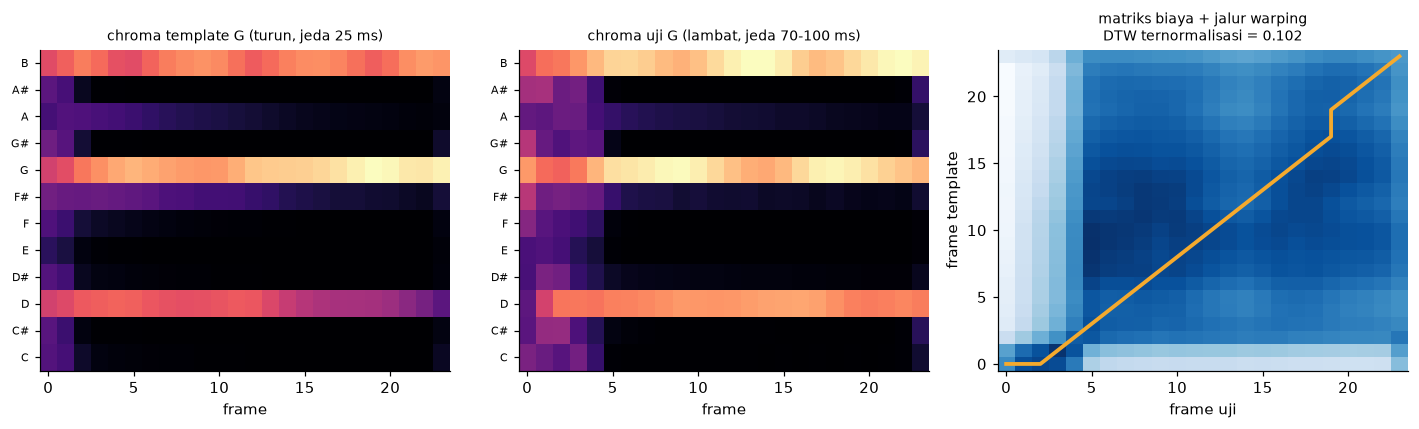

In [33]:
d0 = next(d for d in data2 if d["chord"] == "G" and d["variasi"] == "lambat")
T, F = F_templ2["chroma"][NAMA_CHORD.index("G")], fitur_chroma(d0["x"])
jarak, _, jalur = dtw(T, F)
fig = plt.figure(figsize=(13, 4))
a1, a2, a3 = fig.add_subplot(1, 3, 1), fig.add_subplot(1, 3, 2), fig.add_subplot(1, 3, 3)
for a, M, judul in [(a1, T, "chroma template G (turun, jeda 25 ms)"), (a2, F, "chroma uji G (lambat, jeda 70-100 ms)")]:
    a.imshow(M.T, origin="lower", aspect="auto", cmap="magma"); a.set_title(judul, fontsize=9)
    a.set_yticks(range(12)); a.set_yticklabels(NAMA_NADA, fontsize=7); a.set_xlabel("frame")
C = np.sqrt(((T[:, None] - F[None]) ** 2).sum(-1))
a3.imshow(C, origin="lower", aspect="auto", cmap="Blues_r"); a3.plot(jalur[:, 1], jalur[:, 0], color=WARNA[1], lw=2.5)
a3.set_title(f"matriks biaya + jalur warping\nDTW ternormalisasi = {jarak / (len(T) + len(F)):.3f}", fontsize=9)
a3.set_xlabel("frame uji"); a3.set_ylabel("frame template")
plt.tight_layout(); plt.show()

Pada genjrengan lambat, nada-nada chord muncul satu per satu (terlihat sebagai garis-garis yang mulai menyala bergantian di awal). DTW dapat "menunggu" di awal template sampai semua nada pada bunyi uji muncul, lalu berjalan diagonal setelah bunyinya stabil.

## 2.5 Verifikasi: "Saya mau main chord X, sudah benar belum?"

Inilah bentuk yang paling dekat dengan aplikasi nyata. Pengguna sudah tahu chord yang ingin dimainkan, jadi sistem cukup menjawab **benar** atau **salah**.

1. **Skor** = jarak antara bunyi dan template chord yang dituju. Makin besar skornya, makin besar kemungkinan salah.
2. **Ambang batas**: skor di atas ambang dinyatakan salah.
3. **Evaluasi**:
   - **ROC-AUC**: peluang skor chord salah lebih besar daripada skor chord benar. 0,5 = menebak, 1 = sempurna. Tidak bergantung pada ambang.
   - **Sensitivitas** = proporsi chord salah yang berhasil terdeteksi; **spesifisitas** = proporsi chord benar yang diterima.
   - Ambang dipilih dengan indeks Youden ($J$ = sensitivitas + spesifisitas − 1). Supaya tidak bias, ambang ditentukan **lintas gitar**: gitar uji dibagi dua kelompok, ambang dari kelompok satu diterapkan ke kelompok lain, lalu sebaliknya.

Pembanding skornya: DTW dan Euclid resampling (fitur chroma), DTW fitur semiton, dan baseline template biner ($1 -$ kemiripan kosinus).

In [34]:
def skor_verifikasi(x, c):
    Fc, Fs = fitur_chroma(x), fitur_semiton(x)
    i = NAMA_CHORD.index(c)
    return {"chroma | DTW": dtw_norm(F_templ2["chroma"][i], Fc),
            "chroma | Euclid resampling": euclid_resample(F_templ2["chroma"][i], Fc),
            "semiton | DTW": dtw_norm(F_templ2["semiton"][i], Fs),
            "template biner (baseline)": 1 - kos(Fc[:N_AWAL].mean(0), POLA_BINER[c])}

ver = pd.DataFrame([{"chord": d["chord"], "instrumen": d["instrumen"], "variasi": d["variasi"],
                     "salah": lab, **skor_verifikasi(d["x"], d["chord"])}
                    for kumpulan, lab in [(data2, 0), (salah2, 1)] for d in kumpulan])
SKOR = ["chroma | DTW", "chroma | Euclid resampling", "semiton | DTW", "template biner (baseline)"]

def auc(skor, label):
    # AUC = P(skor salah > skor benar), setara statistik Mann-Whitney
    s1, s0 = skor[label == 1], skor[label == 0]
    return float(((s1[:, None] > s0[None]).sum() + 0.5 * (s1[:, None] == s0[None]).sum()) / (len(s1) * len(s0)))

def ambang_youden(skor, label):
    kandidat = np.unique(skor)
    j = [np.mean(skor[label == 1] > t) + np.mean(skor[label == 0] <= t) - 1 for t in kandidat]
    return kandidat[int(np.argmax(j))]

# ambang lintas gitar (2 kelompok); bila hanya ada 1 gitar uji, ambang dihitung dari data yang sama
kelompok = {inst: i % 2 for i, inst in enumerate(sorted(ver.instrumen.unique()))}
ver["kelompok"] = ver.instrumen.map(kelompok)
lintas = ver.kelompok.nunique() > 1
if not lintas: print("Catatan: hanya 1 gitar uji, ambang dihitung dari data yang sama (hasil cenderung optimis).")
for s in SKOR:
    ver[f"tolak | {s}"] = 0
    for g in ver.kelompok.unique():
        latih = ver[ver.kelompok != g] if lintas else ver
        t = ambang_youden(latih[s].to_numpy(), latih.salah.to_numpy())
        ver.loc[ver.kelompok == g, f"tolak | {s}"] = (ver.loc[ver.kelompok == g, s] > t).astype(int)

baris = []
y_ver = ver.salah.to_numpy()
for s in SKOR:
    tolak = ver[f"tolak | {s}"].to_numpy()
    k_sen, n_sen = int(((tolak == 1) & (y_ver == 1)).sum()), int((y_ver == 1).sum())
    k_spe, n_spe = int(((tolak == 0) & (y_ver == 0)).sum()), int((y_ver == 0).sum())
    baris.append({"skor": s, "ROC-AUC": auc(ver[s].to_numpy(), y_ver),
                  "sensitivitas": k_sen / n_sen, "CI sens.": "[{:.1%}, {:.1%}]".format(*wilson(k_sen, n_sen)),
                  "spesifisitas": k_spe / n_spe, "CI spes.": "[{:.1%}, {:.1%}]".format(*wilson(k_spe, n_spe)),
                  "akurasi verifikasi": (k_sen + k_spe) / (n_sen + n_spe)})
verif = pd.DataFrame(baris).set_index("skor").sort_values("ROC-AUC", ascending=False)
print(f"Verifikasi: {n_spe} chord benar vs {n_sen} chord salah")
tampil(verif, {"ROC-AUC": "{:.3f}", "sensitivitas": "{:.1%}", "spesifisitas": "{:.1%}", "akurasi verifikasi": "{:.1%}"})

Verifikasi: 136 chord benar vs 136 chord salah


,ROC-AUC,sensitivitas,CI sens.,spesifisitas,CI spes.,akurasi verifikasi
skor,,,,,,
semiton | DTW,0.805,73.5%,"[65.5%, 80.2%]",80.9%,"[73.5%, 86.6%]",77.2%
chroma | DTW,0.769,65.4%,"[57.1%, 72.9%]",85.3%,"[78.4%, 90.3%]",75.4%
chroma | Euclid resampling,0.763,64.0%,"[55.6%, 71.6%]",86.8%,"[80.0%, 91.5%]",75.4%
template biner (baseline),0.695,69.1%,"[60.9%, 76.3%]",43.4%,"[35.3%, 51.8%]",56.2%


Proporsi dinyatakan SALAH per kelompok bunyi
(baris chord benar: idealnya 0% = alarm palsu; baris chord salah: idealnya 100% = terdeteksi)


,chroma | DTW,chroma | Euclid resampling,semiton | DTW,template biner (baseline)
variasi,,,,
turun,11.8%,11.8%,17.6%,52.9%
naik,11.8%,11.8%,23.5%,52.9%
lambat,11.8%,14.7%,17.6%,58.8%
derau,23.5%,14.7%,17.6%,61.8%
nada salah,97.1%,97.1%,95.6%,77.9%
senar mati,33.8%,30.9%,51.5%,60.3%


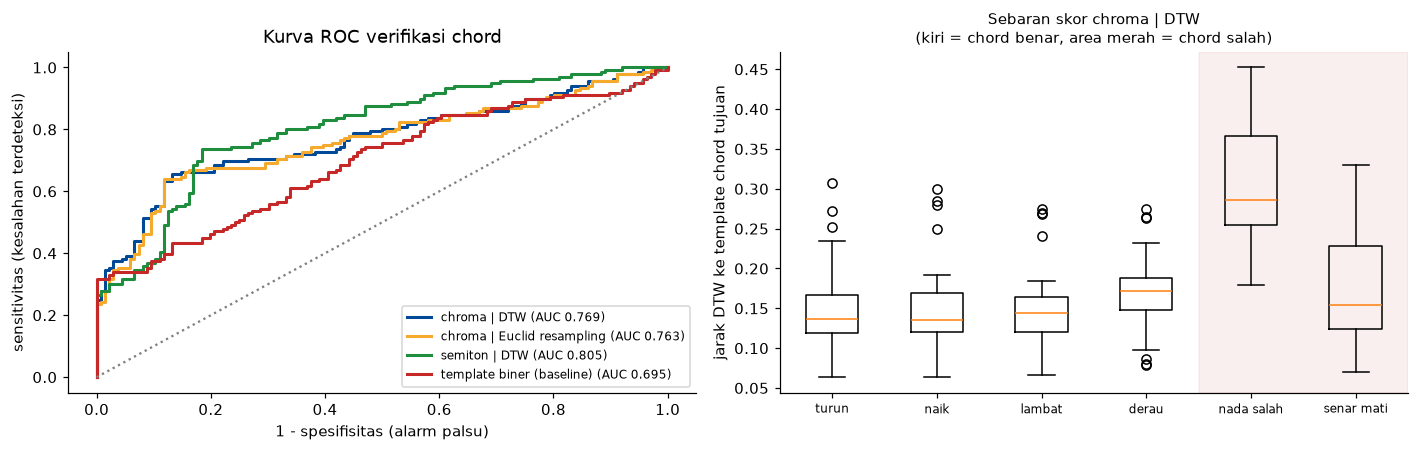

In [35]:
# Rincian: kesalahan jenis apa yang terdeteksi, dan chord benar variasi apa yang salah ditolak
rinci = pd.DataFrame({s: ver.groupby("variasi")[f"tolak | {s}"].mean() for s in SKOR}).reindex(VARIASI2 + ["nada salah", "senar mati"])
print("Proporsi dinyatakan SALAH per kelompok bunyi")
print("(baris chord benar: idealnya 0% = alarm palsu; baris chord salah: idealnya 100% = terdeteksi)")
tampil(rinci, {s: "{:.1%}" for s in SKOR})

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for s, warna in zip(SKOR, [WARNA[0], WARNA[1], WARNA[2], WARNA[3]]):
    sk = ver[s].to_numpy(); t = np.r_[np.inf, np.sort(np.unique(sk))[::-1], -np.inf]
    tpr = [np.mean(sk[y_ver == 1] > v) for v in t]; fpr = [np.mean(sk[y_ver == 0] > v) for v in t]
    ax[0].plot(fpr, tpr, color=warna, lw=2, label=f"{s} (AUC {auc(sk, y_ver):.3f})")
ax[0].plot([0, 1], [0, 1], ":", color="gray"); ax[0].set_xlabel("1 - spesifisitas (alarm palsu)")
ax[0].set_ylabel("sensitivitas (kesalahan terdeteksi)"); ax[0].set_title("Kurva ROC verifikasi chord"); ax[0].legend(fontsize=8)
kel = VARIASI2 + ["nada salah", "senar mati"]
ax[1].boxplot([ver.loc[ver.variasi == k, "chroma | DTW"] for k in kel])
ax[1].set_xticks(range(1, len(kel) + 1)); ax[1].set_xticklabels(kel, fontsize=8)
ax[1].axvspan(len(VARIASI2) + 0.5, len(kel) + 0.5, color=WARNA[3], alpha=0.07)
ax[1].set_title("Sebaran skor chroma | DTW\n(kiri = chord benar, area merah = chord salah)", fontsize=10)
ax[1].set_ylabel("jarak DTW ke template chord tujuan")
plt.tight_layout(); plt.show()

## 2.6 Diagnosis: nada mana yang kurang atau berlebih?
Selain menyatakan benar/salah, aplikasi bisa memberi petunjuk. Profil 12 nada (rata-rata chroma 1,5 detik pertama) dibandingkan dengan profil template chord tujuan:
- nada chord yang energinya **jauh lebih kecil** dari template → kemungkinan **senar mati** atau tidak tertekan;
- nada yang energinya **jauh lebih besar** dari template → kemungkinan **nada salah**.

Ini heuristik sederhana: harmonik nada tetap bisa mengaburkan hasilnya, jadi anggap sebagai petunjuk, bukan kepastian.

In [36]:
def profil12(x):
    v = fitur_chroma(x)[:N_AWAL].mean(0)
    return v / (v.max() + 1e-12)
PROFIL_TEMPL = {c: profil12(audio_templ2[c]) for c in NAMA_CHORD}
T_VERIF = ambang_youden(ver["chroma | DTW"].to_numpy(), y_ver)      # ambang untuk aplikasi (semua data uji)

def cek_chord(x, target, ambang_selisih=0.25, verbose=True):
    skor = dtw_norm(F_templ2["chroma"][NAMA_CHORD.index(target)], fitur_chroma(x))
    tebakan = NAMA_CHORD[int(np.argmin([dtw_norm(T, fitur_chroma(x)) for T in F_templ2["chroma"]]))]
    selisih = profil12(x) - PROFIL_TEMPL[target]
    kurang = [NAMA_NADA[k] for k in range(12) if k in pc(CHORD[target]) and selisih[k] < -ambang_selisih]
    lebih = [NAMA_NADA[k] for k in range(12) if selisih[k] > ambang_selisih]
    benar = skor <= T_VERIF
    if verbose:
        print(f"Target {target:3s} | skor {skor:.3f} (ambang {T_VERIF:.3f}) -> {'BENAR' if benar else 'SALAH'}"
              f" | paling mirip: {tebakan}"
              + (f" | nada kurang: {', '.join(kurang)}" if kurang else "") + (f" | nada berlebih: {', '.join(lebih)}" if lebih else ""))
    return benar, kurang, lebih

print("Contoh chord benar:")
for d in [d for d in data2 if d["variasi"] == "turun"][:3]: cek_chord(d["x"], d["chord"])
print("\nContoh chord salah:")
for d in salah2[:6]:
    asli = ", ".join(nama_nada(p) for p in CHORD[d["chord"]]); jadi = ", ".join(nama_nada(p) for p in d["nada"])
    print(f"[{d['variasi']}] seharusnya {asli} | dimainkan {jadi}")
    print("   ", end=""); cek_chord(d["x"], d["chord"])

Contoh chord benar:
Target D   | skor 0.169 (ambang 0.197) -> BENAR | paling mirip: D
Target A   | skor 0.133 (ambang 0.197) -> BENAR | paling mirip: A | nada berlebih: A
Target Am  | skor 0.141 (ambang 0.197) -> BENAR | paling mirip: Am | nada berlebih: A

Contoh chord salah:
[nada salah] seharusnya D3, A3, D4, F#4 | dimainkan D3, A3, D4, G4
   Target D   | skor 0.344 (ambang 0.197) -> SALAH | paling mirip: D | nada kurang: F# | nada berlebih: C, G
[nada salah] seharusnya D3, A3, D4, F#4 | dimainkan D3, A3, D#4, F#4
   Target D   | skor 0.278 (ambang 0.197) -> SALAH | paling mirip: D | nada berlebih: C, D#
[senar mati] seharusnya D3, A3, D4, F#4 | dimainkan D3, A3, D4
   Target D   | skor 0.298 (ambang 0.197) -> SALAH | paling mirip: D | nada kurang: F#
[senar mati] seharusnya D3, A3, D4, F#4 | dimainkan A3, D4, F#4
   Target D   | skor 0.150 (ambang 0.197) -> BENAR | paling mirip: D
[nada salah] seharusnya A2, E3, A3, C#4, E4 | dimainkan A2, F3, A3, C#4, E4
   Target A   | skor 0.338

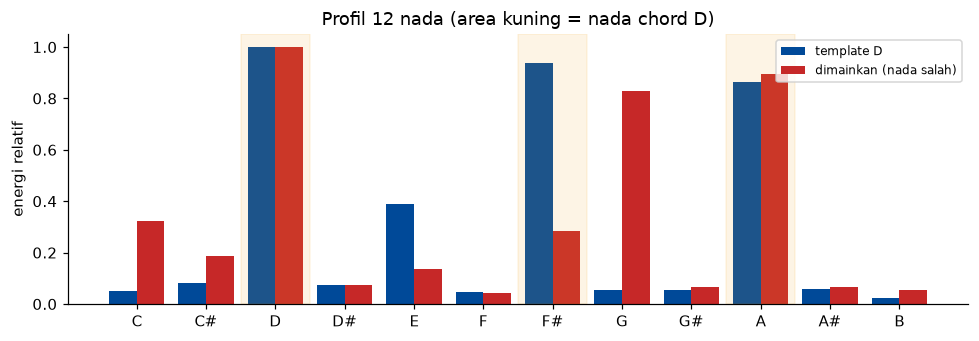

In [37]:
# Visual diagnosis: profil 12 nada template vs satu chord dengan nada salah
d_s = next(d for d in salah2 if d["variasi"] == "nada salah")
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(np.arange(12) - 0.2, PROFIL_TEMPL[d_s["chord"]], 0.4, color=WARNA[0], label=f"template {d_s['chord']}")
ax.bar(np.arange(12) + 0.2, profil12(d_s["x"]), 0.4, color=WARNA[3], label="dimainkan (nada salah)")
for k in pc(CHORD[d_s["chord"]]): ax.axvspan(k - 0.5, k + 0.5, color=WARNA[1], alpha=0.12)
ax.set_xticks(range(12)); ax.set_xticklabels(NAMA_NADA); ax.set_ylabel("energi relatif")
ax.set_title(f"Profil 12 nada (area kuning = nada chord {d_s['chord']})"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 2.7 Jendela Sakoe–Chiba pada chord

In [38]:
baris = []
for band in [None, 10, 5, 2, 1]:
    t0 = time.time()
    pred = np.array([NAMA_CHORD[int(np.argmin([dtw_norm(T, F, band=band) for T in F_templ2["chroma"]]))] for F in F_uji2["chroma"]])
    baris.append({"jendela (frame)": "tanpa" if band is None else band, "akurasi": f"{(pred == y2).mean():.1%}",
                  "akurasi 'lambat'": f"{(pred[lambat] == y2[lambat]).mean():.1%}", "waktu (detik)": round(time.time() - t0, 2)})
display(pd.DataFrame(baris))

,jendela (frame),akurasi,akurasi 'lambat',waktu (detik)
0,tanpa,97.8%,100.0%,0.39
1,10,97.8%,100.0%,0.22
2,5,97.8%,100.0%,0.15
3,2,97.8%,100.0%,0.13
4,1,97.8%,100.0%,0.10


**Pertanyaan untuk tafsiran Bagian 2:**
1. Apakah chroma memang lebih unggul dari semiton untuk chord, kebalikan dari Bagian 1? Mengapa?
2. Pasangan mana yang paling sering tertukar (A/Am, E/Em, D/Dm)? Apa yang membuatnya sulit?
3. Pada variasi **lambat**, apakah DTW unggul nyata dibanding Euclid (lihat McNemar)? Bagaimana jalur warping di 2.4 menjelaskannya?
4. Apakah DTW mengalahkan baseline template biner? Kalau tidak, apa kelebihan baseline (tidak butuh rekaman template) dan kekurangannya?
5. Pada verifikasi, jenis kesalahan mana yang lebih mudah dideteksi, **nada salah** atau **senar mati**? Mengapa senar mati sering lolos? (Petunjuk: nada yang hilang sering masih ada di senar lain pada oktaf berbeda, dan chroma tidak membedakan oktaf.)
6. Berapa alarm palsu pada chord benar yang dimainkan **lambat** atau dengan **derau**? Apakah ambang batasnya perlu dibedakan?

# Ringkasan hasil analisis
Sel ini merangkum angka-angka utama dari kedua bagian untuk ditulis di laporan.

In [39]:
def baris_ringkas(tabel, m):
    r = tabel.loc[m]; return f"{r['akurasi']:.1%} (CI 95% {r['CI 95% bawah']:.1%}-{r['CI 95% atas']:.1%}; F1 makro {r['F1 makro']:.3f})"

print(f"MODE DATA: {MODE}" + ("   <-- data sintetis, JANGAN dilaporkan" if MODE == "sintetis" else ""))
print("=" * 100)
print("BAGIAN 1. TUNER (6 senar lepas)")
print(f"  Data uji             : {len(hasil)} bunyi ({len(uji)} rekaman x {len(VARIASI)} variasi), {uji.instrument_str.nunique()} gitar uji")
print(f"  Metode terbaik       : {akurasi1.index[0]} -> {baris_ringkas(akurasi1, akurasi1.index[0])}")
for m in ["semiton | DTW", "semiton | Euclid resampling", "chroma | DTW", "MFCC | DTW", "YIN (baseline tuner)"]:
    print(f"  {m:28s}: {baris_ringkas(akurasi1, m)}")
_, _, p = mcnemar(y1, pred1["semiton | DTW"], pred1["semiton | Euclid resampling"])
print(f"  McNemar semiton DTW vs Euclid resampling: p = {p:.4f}")
print(f"  Ketepatan cent       : median |cent| asli {np.nanmedian(np.abs(c_asli)):.1f}, variasi fals {np.nanmedian(c_fals):.1f} (target 35)")
print("=" * 100)
print("BAGIAN 2. CEK CHORD (8 chord)")
print(f"  Data uji klasifikasi : {len(hasil2)} genjrengan, {hasil2.instrumen.nunique()} gitar uji")
print(f"  Metode terbaik       : {akurasi2.index[0]} -> {baris_ringkas(akurasi2, akurasi2.index[0])}")
for m in ["chroma | DTW", "chroma | Euclid resampling", "semiton | DTW", "MFCC | DTW", "template biner (baseline)"]:
    print(f"  {m:28s}: {baris_ringkas(akurasi2, m)}")
_, _, p = mcnemar(y2, pred2["chroma | DTW"], pred2["chroma | Euclid resampling"])
print(f"  McNemar chroma DTW vs Euclid resampling: p = {p:.4f}")
b = verif.index[0]
print(f"  Verifikasi terbaik   : {b} -> AUC {verif.loc[b, 'ROC-AUC']:.3f}, sensitivitas {verif.loc[b, 'sensitivitas']:.1%}, "
      f"spesifisitas {verif.loc[b, 'spesifisitas']:.1%}")
print(f"  chroma | DTW         : AUC {verif.loc['chroma | DTW', 'ROC-AUC']:.3f}; deteksi nada salah "
      f"{rinci.loc['nada salah', 'chroma | DTW']:.1%}, senar mati {rinci.loc['senar mati', 'chroma | DTW']:.1%}")

MODE DATA: nsynth
BAGIAN 1. TUNER (6 senar lepas)
  Data uji             : 176 bunyi (44 rekaman x 4 variasi), 7 gitar uji
  Metode terbaik       : YIN (baseline tuner) -> 100.0% (CI 95% 97.9%-100.0%; F1 makro 1.000)
  semiton | DTW               : 93.2% (CI 95% 88.5%-96.1%; F1 makro 0.921)
  semiton | Euclid resampling : 91.5% (CI 95% 86.4%-94.8%; F1 makro 0.907)
  chroma | DTW                : 87.5% (CI 95% 81.8%-91.6%; F1 makro 0.868)
  MFCC | DTW                  : 29.5% (CI 95% 23.3%-36.7%; F1 makro 0.291)
  YIN (baseline tuner)        : 100.0% (CI 95% 97.9%-100.0%; F1 makro 1.000)
  McNemar semiton DTW vs Euclid resampling: p = 0.2500
  Ketepatan cent       : median |cent| asli 5.7, variasi fals 34.3 (target 35)
BAGIAN 2. CEK CHORD (8 chord)
  Data uji klasifikasi : 136 genjrengan, 5 gitar uji
  Metode terbaik       : semiton | Euclid padding -> 100.0% (CI 95% 97.3%-100.0%; F1 makro 0.750)
  chroma | DTW                : 97.8% (CI 95% 93.7%-99.2%; F1 makro 0.726)
  chroma | Eucli

# Lampiran G (opsional). Verifikasi dengan librosa
Bila `librosa` terpasang, kita bandingkan DTW dan YIN buatan sendiri dengan versi pustaka.

In [41]:
pip install librosa

   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ------- -------------------------------- 0.5/2.8 MB 1.4 MB/s eta 0:00:02
   ----------- ---------------------------- 0.8/2.8 MB 1.3 MB/s eta 0:00:02
   ----------- ---------------------------- 0.8/2.8 MB 1.3 MB/s eta 0:00:02
   -------------- ------------------------- 1.0/2.8 MB 1.2 MB/s eta 0:00:02
   ------------------ --------------------- 1.3/2.8 MB 1.1 MB/s eta 0:00:02
   ---------------------- ----------------- 1.6/2.8 MB 1.1 MB/s eta 0:00:02
   ------------------------- -------------- 1.8/2.8 MB 1.1 MB/s eta 0:00:01
   ----------------------------- ---------- 2.1/2.8 MB 1.2 MB/s eta 0:00:01
   --------------------------------- ------ 2.4/2.8 MB 1.2 MB/s eta 0:00:01
   ------------------------------------- -- 2.6/2.8 MB 1.2 MB/s eta 0:00:01
   ---------------------------------------- 2.8/2.8 MB 1.2 MB/s eta 0:00:00
   -----------------------


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [42]:
try:
    import librosa
    A, B = F_templ["semiton"][1], F_uji["semiton"][0]
    D_lib, _ = librosa.sequence.dtw(X=A.T, Y=B.T, metric="euclidean")
    print("DTW kita    :", round(dtw(A, B)[0], 6))
    print("DTW librosa :", round(float(D_lib[-1, -1]), 6))
    for p in PITCH:
        f_lib = np.nanmedian(librosa.pyin(audio_templ[p][:SR], fmin=60, fmax=1000, sr=SR)[0])
        print(f"{SENAR[p]}: YIN kita {yin_f0(audio_templ[p]):6.1f} Hz | pYIN librosa {f_lib:6.1f} Hz")
except ImportError:
    print("librosa tidak terpasang: verifikasi dilewati (pip install librosa).")

DTW kita    : 35.460549
DTW librosa : 35.460549
E2: YIN kita   82.6 Hz | pYIN librosa   82.4 Hz
A2: YIN kita  110.1 Hz | pYIN librosa  110.0 Hz
D3: YIN kita  147.0 Hz | pYIN librosa  146.9 Hz
G3: YIN kita  196.6 Hz | pYIN librosa  197.2 Hz
B3: YIN kita  248.2 Hz | pYIN librosa  248.5 Hz
E4: YIN kita  330.7 Hz | pYIN librosa  331.7 Hz


# Lampiran H (opsional). Uji dengan rekaman gitar sendiri
Rekam dengan ponsel (ubah ke WAV), simpan di folder `rekaman_saya/`:
- petikan satu senar: `<nada>_<nomor>.wav`, misalnya `E2_1.wav`, `A2_3.wav` → dijalankan dengan tuner (Bagian 1);
- genjrengan chord: `chord_<nama>_<nomor>.wav`, misalnya `chord_G_1.wav`, `chord_Am_2.wav` → dicek dengan `cek_chord` (Bagian 2). Nama chord yang dikenal: C, D, E, G, A, Am, Em, Dm.

Untuk menguji deteksi kesalahan, rekam juga beberapa genjrengan yang sengaja salah, misalnya satu jari digeser satu fret.

In [45]:
from scipy.signal import butter, sosfiltfilt

def bersihkan(x, fc=70):
    x = x - np.mean(x)
    return sosfiltfilt(butter(4, fc, "highpass", fs=SR, output="sos"), x)

def f0_harmonik(x, f_target, lebar_cent=100, n_harm=6, detik=1.5):
    # cari f0 di sekitar senar target (±1 semitone) dengan menjumlahkan energi di harmoniknya
    seg = x[:int(detik * SR)]; seg = (seg - seg.mean()) * np.hanning(len(seg))
    n = 1 << 18; S = np.abs(rfft(seg, n)); f = rfftfreq(n, 1 / SR)
    kandidat = f_target * 2 ** (np.linspace(-lebar_cent, lebar_cent, 801) / 1200)
    skor = sum(np.interp(k * kandidat, f, S) / k for k in range(1, n_harm + 1))
    return float(kandidat[int(np.argmax(skor))])

def tuner_rekaman(x, nama=""):
    x = bersihkan(x)
    p = PITCH[int(np.argmin([dtw_norm(T, fitur_semiton(x)) for T in F_templ["semiton"]]))]  # DTW: senar apa
    f0 = f0_harmonik(x, midi_ke_hz(p))                                                       # harmonik: berapa cent
    cent = 1200 * np.log2(f0 / midi_ke_hz(p))
    status = "PAS" if abs(cent) < 5 else ("terlalu rendah -> kencangkan" if cent < 0 else "terlalu tinggi -> kendurkan")
    print(f"{nama:16s} senar {SENAR[p]} ({midi_ke_hz(p):5.1f} Hz) | f0 {f0:6.1f} Hz | {cent:+6.1f} cent | {status}")
    return p, cent

def profil_bersih(x):
    v = fitur_chroma(x)[:N_AWAL].mean(0)
    v = np.clip(v - np.median(v), 0, None)               # buang "lantai" derau
    return v / (v.max() + 1e-12)

def cek_chord_rekaman(x, target, nama=""):
    x = bersihkan(x); Fc = fitur_chroma(x)
    jarak = [dtw_norm(T, Fc) for T in F_templ2["chroma"]]
    terdekat = NAMA_CHORD[int(np.argmin(jarak))]
    v = profil_bersih(x); nada = pc(CHORD[target])
    kurang = [NAMA_NADA[k] for k in sorted(nada) if v[k] < 0.3]
    lebih = [NAMA_NADA[k] for k in range(12) if k not in nada and v[k] > 0.5]
    print(f"{nama:16s} target {target:3s} | paling mirip: {terdekat:3s} -> {'BENAR' if terdekat == target else 'SALAH'}"
          + (f" | cek nada kurang: {', '.join(kurang)}" if kurang else "") + (f" | cek nada berlebih: {', '.join(lebih)}" if lebih else ""))
    return terdekat == target

label_dari_nama = lambda f: os.path.splitext(f)[0].split("_")
if os.path.isdir("rekaman_saya"):
    file = sorted(f for f in os.listdir("rekaman_saya") if f.lower().endswith(".wav"))
    senar_f = [f for f in file if not f.lower().startswith("chord_")]
    chord_f = [f for f in file if f.lower().startswith("chord_")]
    benar = sum(SENAR[tuner_rekaman(pangkas_sunyi(muat(f"rekaman_saya/{f}")), f)[0]] == label_dari_nama(f)[0].upper() for f in senar_f)
    if senar_f: print(f"Akurasi senar: {benar}/{len(senar_f)}\n")
    benar = sum(cek_chord_rekaman(pangkas_sunyi(muat(f"rekaman_saya/{f}")), label_dari_nama(f)[1], f)
                for f in chord_f if label_dari_nama(f)[1] in CHORD)
    if chord_f: print(f"Akurasi chord: {benar}/{len(chord_f)}")

A2.wav           senar A2 (110.0 Hz) | f0  110.0 Hz |   +0.7 cent | PAS
B3.wav           senar B3 (246.9 Hz) | f0  248.3 Hz |   +9.2 cent | terlalu tinggi -> kendurkan
D3.wav           senar D3 (146.8 Hz) | f0  146.7 Hz |   -1.0 cent | PAS
E2.wav           senar E2 ( 82.4 Hz) | f0   80.9 Hz |  -31.3 cent | terlalu rendah -> kencangkan
E4.wav           senar E2 ( 82.4 Hz) | f0   78.4 Hz |  -86.2 cent | terlalu rendah -> kencangkan
G3.wav           senar G3 (196.0 Hz) | f0  193.8 Hz |  -19.3 cent | terlalu rendah -> kencangkan
Akurasi senar: 5/6

chord_A.wav      target A   | paling mirip: A   -> BENAR | cek nada kurang: E, A | cek nada berlebih: D, A#
chord_D.wav      target D   | paling mirip: D   -> BENAR | cek nada kurang: D, F#, A | cek nada berlebih: B
chord_G.wav      target G   | paling mirip: G   -> BENAR | cek nada kurang: D, G
Akurasi chord: 3/3


# Latihan dan pengembangan
1. **Template ganda.** Pakai beberapa template per senar (misalnya dari 2–3 gitar atau 3 velocity) dan k-NN. Apakah akurasi pada gitar elektrik/sintetis naik?
2. **Kelas lebih banyak.** Perluas dari 6 senar menjadi semua nada di fret 0–12 (MIDI 40–76). Fitur mana yang tetap bertahan?
3. **Fals ekstrem.** Ubah geseran variasi `fals` menjadi ±45 cent. Di titik mana senar mulai tertukar dengan nada tetangga?
4. **Derivative DTW.** Pakai `np.diff` pada fitur sebelum DTW. Apakah membantu pada variasi `derau`?
5. **Rekaman sendiri** (Lampiran H): bandingkan akurasi pada gitar sungguhan dengan hasil NSynth.
6. **Chord lebih banyak.** Tambahkan F (barre: 1 3 3 2 1 1 → 41 48 53 57 60 65), B7, atau chord septim. Mana yang paling sering tertukar?
7. **Template chord ganda.** Pakai template genjrengan turun dan naik untuk tiap chord. Apakah alarm palsu pada variasi `naik` berkurang?
8. **Ambang per chord.** Tentukan ambang verifikasi terpisah untuk setiap chord. Apakah sensitivitas dan spesifisitas membaik?

## Referensi
- Sakoe, H., & Chiba, S. (1978). Dynamic programming algorithm optimization for spoken word recognition. *IEEE Trans. ASSP, 26*(1), 43–49.
- Engel, J., dkk. (2017). Neural audio synthesis of musical notes with WaveNet autoencoders. *ICML* (dataset NSynth).
- de Cheveigné, A., & Kawahara, H. (2002). YIN, a fundamental frequency estimator for speech and music. *JASA, 111*(4), 1917–1930.
- Karplus, K., & Strong, A. (1983). Digital synthesis of plucked-string and drum timbres. *Computer Music Journal, 7*(2), 43–55.
- Müller, M. (2015). *Fundamentals of Music Processing*. Springer (fitur chroma dan DTW untuk musik).